**Philippines 2025 Article IV: IMF report to dashboard**

This notebook uses IMF Country Report No. 25/333. Keep `data/` next to it, and `cache/` if you have it, then choose Run all.

**Step 1. Packages**

Only pypdf and faiss-cpu need installing. Their versions are fixed so the PDF text stays the same.

In [1]:
%pip install -q pypdf==6.21.4 faiss-cpu==1.15.1

**Step 1b. Settings**

All the settings are in one block, so a change needs only one line.

In [2]:
import configparser
import hashlib
import json
import os
import re
import string
import textwrap
import time
import types
from bisect import bisect_right
from collections import Counter
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SETTINGS_INI = """
[report]
pdf = data/philippines_cr25333.pdf
country = Philippines
label = IMF Country Report No. 25/333, 2025 Article IV

[models]
writer = gemini-3.7-flash
judge = gemini-3.6-flash
temperature = 0.1
max_output_tokens = 4096
retries = 5

[run]
# auto = use the cache and call the API only for missing replies; replay = cache only, never call the API
mode = auto
cache_dir = cache/replies
out_dir = artefacts

[text]
embedder = sentence-transformers/multi-qa-distilbert-cos-v1
chunk_tokens = 380
overlap_tokens = 75
summary_words = 100
top_k = 5
# dense candidates rescored with word overlap (0 = dense only)
rerank_pool = 20
lexical_weight = 0.2
"""


def read_settings(ini_text: str) -> types.SimpleNamespace:
    """Parse the INI block; numbers become int or float, everything else stays a string."""
    parser = configparser.ConfigParser()
    parser.read_string(ini_text)
    values = {}
    for block in parser.sections():
        for key, raw in parser[block].items():
            for kind in (int, float, str):
                try:
                    values[key] = kind(raw)
                    break
                except ValueError:
                    pass
    return types.SimpleNamespace(**values)


opt = read_settings(SETTINGS_INI)
opt.mode = os.environ.get("PH_RUN_MODE", opt.mode)

OUT = Path(opt.out_dir)
(OUT / "json").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(parents=True, exist_ok=True)
Path(opt.cache_dir).mkdir(parents=True, exist_ok=True)

PDF = Path(opt.pdf)
assert PDF.exists(), f"The report is missing: upload the data/ folder so that {PDF} exists."
PDF_SHA256 = hashlib.sha256(PDF.read_bytes()).hexdigest()


def save(name: str, payload) -> Path:
    """Write one artefact as pretty JSON under artefacts/json/."""
    target = OUT / "json" / f"{name}.json"
    target.write_text(json.dumps(payload, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    return target


print(f"PDF      {PDF}  sha256 {PDF_SHA256[:16]}...")
print(f"writer   {opt.writer}\njudge    {opt.judge}\nembedder {opt.embedder}")
print(f"chunks   {opt.chunk_tokens} tokens, overlap {opt.overlap_tokens}")

PDF      data/philippines_cr25333.pdf  sha256 e65a1158a09333e7...
writer   gemini-3.7-flash
judge    gemini-3.6-flash
embedder sentence-transformers/multi-qa-distilbert-cos-v1
chunks   380 tokens, overlap 75


**Step 2. Model layer**

The writer and the judge are two different Flash models. Every reply is saved, so a second run makes no new calls.

In [3]:
import jsonschema
from datetime import datetime, timezone

PROMPTS: dict = {}
CALLS: list = []
LLM = {"transport": None, "native_schema": True}


class ReplayMiss(RuntimeError):
    """A reply was needed but the cache does not have it and live calls are switched off."""


def add_prompt(name: str, system: str, user: str) -> str:
    PROMPTS[name] = {"system": textwrap.dedent(system).strip(), "user": string.Template(textwrap.dedent(user).strip())}
    return name


def jobject(title: str | None, props: dict, optional: tuple = ()) -> dict:
    schema = {"type": "object", "properties": props,
              "required": [k for k in props if k not in optional], "additionalProperties": False}
    if title:
        schema["title"] = title
    return schema


def jlist(item: dict, lo: int | None = None, hi: int | None = None) -> dict:
    out = {"type": "array", "items": item}
    if lo is not None:
        out["minItems"] = lo
    if hi is not None:
        out["maxItems"] = hi
    return out


SCORE = {"type": "integer", "minimum": 1, "maximum": 5}
TEXT = {"type": "string"}


def colab_key():
    try:
        from google.colab import userdata
        return userdata.get("GEMINI_API_KEY")
    except Exception:
        return os.environ.get("GEMINI_API_KEY")


def gemini_transport(model: str, system: str, user: str, schema: dict) -> tuple[str, int]:
    """One live request through google-genai. The client is kept in a named variable for the call."""
    from google import genai
    from google.genai import types as gtypes
    client = genai.Client(api_key=colab_key())
    settings = dict(system_instruction=system, temperature=opt.temperature,
                    max_output_tokens=opt.max_output_tokens, response_mime_type="application/json")
    if LLM["native_schema"]:
        settings["response_json_schema"] = schema
    response = client.models.generate_content(model=model, contents=user,
                                              config=gtypes.GenerateContentConfig(**settings))
    usage = getattr(response, "usage_metadata", None)
    return response.text or "", int(getattr(usage, "candidates_token_count", 0) or 0)


LLM["transport"] = gemini_transport
if opt.mode == "auto" and not colab_key():
    opt.mode = "replay"


def reply_path(key: str) -> Path:
    return Path(opt.cache_dir) / key[:2] / f"{key}.json"


def fetch(step: str, role: str, model: str, system: str, user: str, schema: dict) -> str:
    """Return the reply text from the cache, or make a live call and store it."""
    key = hashlib.sha256(json.dumps([model, system, user, schema], sort_keys=True).encode("utf-8")).hexdigest()
    path = reply_path(key)
    if path.exists():
        stored = json.loads(path.read_text(encoding="utf-8"))
        CALLS.append({"step": step, "role": role, "model": model, "source": "cache", "seconds": 0.0,
                      "tokens": stored["tokens"], "key": key[:10]})
        return stored["reply"]
    if opt.mode == "replay":
        raise ReplayMiss(f"no cached reply for '{step}'. Upload cache/ or add the GEMINI_API_KEY secret.")
    error = None
    for attempt in range(1, opt.retries + 1):
        started = time.perf_counter()
        try:
            text, tokens = LLM["transport"](model, system, user, schema)
            if not text.strip():
                raise RuntimeError("empty reply")
            break
        except Exception as exc:
            error = exc
            if LLM["native_schema"] and "schema" in str(exc).lower():
                LLM["native_schema"] = False  # older API version: keep the schema in the prompt only
                print(f"  [{step}] native schema refused, schema now sent in the prompt only")
                continue
            pause = min(90, 4 * 2 ** attempt)
            print(f"  [{step}] attempt {attempt} failed: {type(exc).__name__} {str(exc)[:100]}; waiting {pause}s")
            time.sleep(pause)
    else:
        raise RuntimeError(f"'{step}' failed {opt.retries} times") from error
    seconds = round(time.perf_counter() - started, 2)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps({"step": step, "model": model, "reply": text, "tokens": tokens, "seconds": seconds,
                                "saved": datetime.now(timezone.utc).isoformat()}, ensure_ascii=False), encoding="utf-8")
    CALLS.append({"step": step, "role": role, "model": model, "source": "live", "seconds": seconds,
                  "tokens": tokens, "key": key[:10]})
    return text


def as_json(text: str, schema: dict):
    body = text.strip()
    if body.startswith("```"):
        body = body.strip("`").removeprefix("json").strip()
    start, end = body.find("{"), body.rfind("}")
    if start < 0 or end < start:
        raise ValueError("the reply holds no JSON object")
    data = json.loads(body[start:end + 1])
    jsonschema.validate(data, schema)
    return data


def call_model(step: str, prompt_name: str, schema: dict, *, role: str, check=None, **fields):
    """Fill a registered prompt, send it to the writer or the judge, and return validated JSON.
    `check(data)` may raise ValueError for rules a schema cannot express; that also triggers the repair round."""
    model = opt.writer if role == "writer" else opt.judge
    system = PROMPTS[prompt_name]["system"]
    user = (PROMPTS[prompt_name]["user"].substitute(**fields)
            + "\n\nReturn only one JSON object that is valid against this JSON Schema:\n" + json.dumps(schema))
    reply = fetch(step, role, model, system, user, schema)
    try:
        data = as_json(reply, schema)
        if check:
            check(data)
        return data
    except (ValueError, jsonschema.ValidationError) as problem:
        reason = str(problem).splitlines()[0][:400]
        print(f"  [{step}] reply rejected ({reason[:90]}); repair round")
        retry = (user + f"\n\nYour previous answer was rejected for this reason: {reason}\n"
                 f"Previous answer:\n{reply[:3500]}\n\nSend the corrected JSON object only.")
        data = as_json(fetch(step + "/repair", role, model, system, retry, schema), schema)
        if check:
            check(data)
        return data


ask_writer = partial(call_model, role="writer")
ask_judge = partial(call_model, role="judge")


def call_totals() -> dict:
    log = pd.DataFrame(CALLS, columns=["step", "role", "model", "source", "seconds", "tokens", "key"])
    return {"mode": opt.mode, "calls": len(log), "live": int((log.source == "live").sum()),
            "cached": int((log.source == "cache").sum()), "repairs": int(log.step.str.endswith("/repair").sum()),
            "live_seconds": round(float(log.seconds.sum()), 1), "output_tokens": int(log.tokens.sum())}


print(f"run mode: {opt.mode}  (cache folder {opt.cache_dir}, {sum(1 for _ in Path(opt.cache_dir).rglob('*.json'))} replies stored)")

run mode: replay  (cache folder cache/replies, 160 replies stored)


**Step 3. Read the PDF**

I read each page with pypdf and keep its PDF page number. Pages with almost no text are flagged.

In [4]:
from pypdf import PdfReader

FOOTER = re.compile(r"^\s*(?:(\d{1,3})\s+INTERNATIONAL MONETARY FUND|INTERNATIONAL MONETARY FUND\s+(\d{1,3}))\s*$")


def printed_page(text: str):
    """Printed page number from the 'INTERNATIONAL MONETARY FUND n' footer, or None."""
    lines = text.splitlines()
    for line in lines[:4] + lines[-3:]:
        hit = FOOTER.match(line)
        if hit:
            return int(hit.group(1) or hit.group(2))
    return None


reader = PdfReader(PDF)
pages = pd.DataFrame({"pdf_page": range(1, len(reader.pages) + 1),
                      "raw": [pg.extract_text() or "" for pg in reader.pages]})
pages["printed"] = pages["raw"].map(printed_page).astype("Int64")
pages["raw_words"] = pages["raw"].str.split().str.len()
pages["little_text"] = pages["raw_words"] < 40

print(f"{len(pages)} pages, {pages.raw_words.sum():,} words as extracted")
print("pages with almost no text layer:", pages.loc[pages.little_text, "pdf_page"].tolist())
gap = (pages["pdf_page"] - pages["printed"]).dropna().astype(int)
print("PDF page minus printed page:", gap.value_counts().to_dict())

85 pages, 26,227 words as extracted
pages with almost no text layer: [44, 45, 60, 61, 62, 63, 64, 65, 77, 80]
PDF page minus printed page: {5: 70, 76: 3}


**Step 4. Clean the text**

This removes headers and footers and repairs broken words and lines.

In [5]:
FIX_COUNTS: Counter = Counter()
FIX_SAMPLES: dict = {}


def tally(kind: str, sample: str = "") -> None:
    FIX_COUNTS[kind] += 1
    bucket = FIX_SAMPLES.setdefault(kind, [])
    if sample and len(bucket) < 4:
        bucket.append(sample)


CHAR_MAP = {"\u00a0": " ", "\u00ad": "", "\ufb01": "fi", "\ufb02": "fl", "\u2019": "'", "\u2018": "'",
            "\u201c": '"', "\u201d": '"', "\u2026": "..."}
DASHES = {"\u2013": "-", "\u2012": "-", "\u2212": "-", "\u02d7": "-", "\u2014": " - "}
LEADER = re.compile(r"_{3,}")
NUMBERS_ONLY = re.compile(r"^[\s\d.,%()+/:;*\-]*\d[\s\d.,%()+/:;*\-]*$")
SPLIT_DECIMAL = re.compile(r"(?<=\d)(?:\. | \.)(?=\d\b)")  # "19. 8" or "2 .4" inside a row of numbers
ALPHA = re.compile(r"[A-Za-z]+")


def first_pass(text: str) -> list[str]:
    """Character fixes, header, footer and bare page number removal. Returns the page as lines."""
    for bad, good in {**CHAR_MAP, **DASHES}.items():
        if bad in text:
            tally("dash normalised" if bad in DASHES else "odd character replaced", repr(bad))
            text = text.replace(bad, good)
    lines = [ln.rstrip() for ln in text.splitlines()]
    kept, top = [], True
    for ln in lines:
        bare = ln.strip()
        if top and bare == "PHILIPPINES":
            tally("running header removed")
            continue
        if FOOTER.match(ln):
            tally("IMF footer removed", bare)
            continue
        if top and re.fullmatch(r"\d{1,2}", bare):
            tally("bare page number removed", bare)
            continue
        if bare:
            top = False
        kept.append(ln)
    return kept


line_pages = [first_pass(t) for t in pages["raw"]]

VOCAB = Counter(w.lower() for page in line_pages for ln in page for w in ALPHA.findall(ln))


def is_word(token: str) -> bool:
    low = token.lower()
    return low in {"a", "i"} or (len(low) > 1 and VOCAB[low] >= 2)


def should_join(a: str, b: str) -> bool:
    """True when a + b looks like one word that pypdf split: at least one piece is not a word in this
    report and the joined form is. A real word followed by a single letter is left alone."""
    if not (a.isalpha() and b.isalpha()) or (is_word(a) and is_word(b)):
        return False
    single = any(len(t) == 1 and t.lower() not in {"a", "i"} for t in (a, b))
    if is_word(a) and len(b) == 1:
        return False
    return VOCAB[(a + b).lower()] >= (1 if single else 2)


ABBREV = re.compile(r"\b(e|i)\. (g|e)\.")


def join_abbrev(hit: re.Match) -> str:
    tally("split abbreviation rejoined", hit.group(0))
    return f"{hit.group(1)}.{hit.group(2)}."


def repair_inline(line: str) -> str:
    """Join pieces inside one line, e.g. 't he', 'e xemption', 'non-in vestment'."""
    line = ABBREV.sub(join_abbrev, line)
    tokens = line.split(" ")
    out, k = [], 0
    while k < len(tokens):
        a = tokens[k]
        b = tokens[k + 1] if k + 1 < len(tokens) else ""
        a_core = re.search(r"(?:^|-)([A-Za-z]+)$", a)
        b_core = re.match(r"([A-Za-z]+)[.,;:)']*$", b)
        if a_core and b_core and should_join(a_core.group(1), b_core.group(1)):
            tally("split word rejoined (inside a line)", f"{a} {b}")
            out.append(a + b)
            k += 2
            continue
        out.append(a)
        k += 1
    return " ".join(out)


def repair_edges(lines: list[str]) -> list[str]:
    """Join a word broken across two lines, e.g. 'dow' / 'nward', 'I' / 'MF', '2025Q' / '3.'."""
    lines = list(lines)
    for k in range(len(lines) - 1):
        left, right = lines[k].rstrip(), lines[k + 1].lstrip()
        if not left or not right:
            continue
        tail = re.search(r"([A-Za-z0-9]+)$", left)
        head = re.match(r"([A-Za-z]+|/\d+|\d\b)", right)
        if not tail or not head:
            continue
        x, y = tail.group(1), head.group(1)
        joined = y.startswith("/") or (re.fullmatch(r"\d{4}Q", x) and y.isdigit()) or should_join(x, y)
        if joined:
            tally("split word rejoined (across lines)", f"{x}|{y}")
            rest = right[len(y):]
            stick = re.match(r"[.,;:)]+", rest)
            if stick:
                y, rest = y + stick.group(0), rest[stick.end():]
            lines[k] = left + y
            lines[k + 1] = rest.lstrip()
    return [ln for ln in lines if ln.strip() or ln == ""]


def repair_numbers(line: str) -> str:
    if len(re.findall(r"\d+\.\d", line)) >= 2 and SPLIT_DECIMAL.search(line):
        tally("split decimal rejoined", line.strip()[-40:])
        line = SPLIT_DECIMAL.sub(".", line)
    return line


def line_layer(lines: list[str]) -> list[str]:
    lines = repair_edges(lines)
    return [repair_numbers(repair_inline(ln)) for ln in lines]


NEW_BLOCK = re.compile(r"^(\u2022|o |\d{1,2}\.\s|[A-E]\.\s+[A-Z]|\d{1,2} [A-Z]|Authorities' Views|Table \d|Figure \d|Annex [IVX]+)")


def looks_like_heading(text: str) -> bool:
    return text.isupper() and sum(ch.isalpha() for ch in text) >= 4 and len(text) < 70


def prose_layer(lines: list[str]) -> str:
    """Drop leaders and number-only lines, then join soft line breaks into paragraphs."""
    paragraphs, current = [], ""
    for ln in lines:
        text = ln.strip()
        if LEADER.search(text):
            tally("contents leader line removed")
            continue
        if text and NUMBERS_ONLY.match(text):
            tally("number-only line removed (chart axis or year row)")
            continue
        if not text:
            if current:
                paragraphs.append(current)
                current = ""
            continue
        if current and (NEW_BLOCK.match(text) or looks_like_heading(text) or looks_like_heading(current)):
            paragraphs.append(current)
            current = text
        elif current.endswith("-") and current[-2:-1].isalpha():
            tally("line-end hyphen kept (compound word)", current[-15:] + text[:10])
            current += text
        elif current:
            tally("soft line break joined")
            current += " " + text
        else:
            current = text
    if current:
        paragraphs.append(current)
    return "\n".join(re.sub(r"\s{2,}", " ", p) for p in paragraphs)


pages["lines"] = ["\n".join(line_layer(lp)) for lp in line_pages]
pages["clean"] = [prose_layer(lp.split("\n")) for lp in pages["lines"]]
pages["clean_words"] = pages["clean"].str.split().str.len()

assert not pages["clean"].str.contains("INTERNATIONAL MONETARY FUND \\d|\\d INTERNATIONAL MONETARY FUND", regex=True).any()
assert not pages["clean"].str.contains("_____").any()
assert not pages["clean"].str.contains("\u2013|\u2014", regex=True).any()

cleaning = {"pdf_sha256": PDF_SHA256, "pages": len(pages),
            "characters_raw": int(pages["raw"].str.len().sum()), "characters_clean": int(pages["clean"].str.len().sum()),
            "fixes": dict(FIX_COUNTS.most_common()), "examples": FIX_SAMPLES}
save("cleaning", cleaning)
print(pd.Series(FIX_COUNTS).sort_values(ascending=False).to_string())
for kind in ("split word rejoined (inside a line)", "split word rejoined (across lines)", "split decimal rejoined"):
    print(f"{kind}: {FIX_SAMPLES.get(kind, [])}")
print("\nPDF page 2 after cleaning, first paragraphs:")
for para in pages.loc[1, "clean"].split("\n")[3:6]:
    print(textwrap.fill(para, 110, initial_indent="  ", subsequent_indent="  "))

soft line break joined                               2254
odd character replaced                                 78
running header removed                                 75
IMF footer removed                                     73
contents leader line removed                           40
dash normalised                                        29
split word rejoined (inside a line)                    21
number-only line removed (chart axis or year row)      16
split word rejoined (across lines)                     14
line-end hyphen kept (compound word)                   12
bare page number removed                                7
split decimal rejoined                                  2
split abbreviation rejoined                             2
split word rejoined (inside a line): ['t he', 'non-in vestment', 'top-u p', 'e xemption']
split word rejoined (across lines): ['PR25|/418', 'dow|nward', '2025Q|3', 'gov|ernment']
split decimal rejoined: ['period average) 6.6 3.0 2 .4 2.6 2.8 3.0'

**Step 5. Find the sections**

Headings come from the contents list. Parts outside the staff report are found by their titles.

In [6]:
TOC_LINE = re.compile(r"^(?P<ti" r"tle>\S.*?)\s*_{3,}\s*(?P<page>\d{1,3})\s*$")
GROUPS = {"FIGURES", "TABLES", "ANNEXES"}

toc_pages = [p for p, text in zip(pages.pdf_page, pages.raw) if len(re.findall(r"_{10,}", text)) >= 3]
toc_pages = [p for p in toc_pages if p - toc_pages[0] <= 2]  # first block only (the staff report's own list)
gap = int((pages.pdf_page - pages.printed).dropna().astype(int).mode().iloc[0])

toc, group = [], "MAIN"
for p in toc_pages:
    for ln in first_pass(pages.loc[p - 1, "raw"]):
        bare = ln.strip()
        if bare in GROUPS:
            group = bare
            continue
        hit = TOC_LINE.match(bare)
        if hit:
            toc.append({"group": group, "title": " ".join(hit["title"].split()), "pdf_page": int(hit["page"]) + gap})

entries = []
for k, e in enumerate(toc):
    nxt = toc[k + 1] if k + 1 < len(toc) else None
    if e["group"] == "MAIN":
        is_parent = e["title"].isupper() and nxt and re.match(r"^[A-E]\. ", nxt["title"]) and nxt["pdf_page"] == e["pdf_page"]
        if is_parent:
            nxt["anchor"] = e["title"]  # the lettered sub-section starts at the parent heading
            continue
        entries.append({"title": e["title"].capitalize() if e["title"].isupper() else e["title"],
                        "anchor": e.get("anchor", e["title"]), "pdf_page": e["pdf_page"], "kind": "staff report"})
    elif e["group"] == "ANNEXES":
        number = e["title"].split(".")[0]
        entries.append({"title": "Annex " + e["title"], "anchor": f"Annex {number}.", "pdf_page": e["pdf_page"], "kind": "annex"})
for grp, label, anchor in (("FIGURES", "Figures", "Figure 1."), ("TABLES", "Statistical tables", "Table 1.")):
    members = [e for e in toc if e["group"] == grp]
    entries.append({"title": f"{label} 1-{len(members)}", "anchor": anchor, "pdf_page": members[0]["pdf_page"], "kind": grp.lower()})

LANDMARKS = [("Press release", r"FOR IMMEDIATE RELEASE", "press release"),
             ("Key issues and staff report front matter", r"\bKEY ISSUES\b", "staff report"),
             ("Informational annex", r"INFORMATIONAL ANNEX", "informational annex"),
             ("Statement by the IMF Staff Representative", r"(?m)^Statement by the IMF Staff Representative\b", "statement"),
             ("Statement by the Executive Director", r"(?m)^Statement by M(?:r|s|rs)\. ", "statement")]
for title, pattern, kind in LANDMARKS:
    page = next(p for p, text in zip(pages.pdf_page, pages.clean) if p > 1 and re.search(pattern, text))
    entries.append({"title": title, "anchor": None, "pdf_page": page, "kind": kind})

# one long document string; page_starts maps a character position back to its PDF page
DOC = ""
page_starts = []
for text in pages.clean:
    page_starts.append(len(DOC))
    DOC += text + "\n\n"


def page_of(pos: int) -> int:
    return bisect_right(page_starts, pos)


def anchor_position(entry: dict) -> int:
    start = page_starts[entry["pdf_page"] - 1]
    if not entry["anchor"]:
        return start
    body = pages.loc[entry["pdf_page"] - 1, "clean"]
    flexible = r"\s+".join(map(re.escape, entry["anchor"].split()))
    hit = re.search(flexible, body) or re.search(flexible, body, re.I)
    assert hit, f"heading '{entry['anchor']}' not found on PDF page {entry['pdf_page']}"
    return start + hit.start()


for e in entries:
    e["start"] = anchor_position(e)
entries.sort(key=lambda e: e["start"])
rows = []
for k, e in enumerate(entries):
    end = entries[k + 1]["start"] if k + 1 < len(entries) else len(DOC)
    text = DOC[e["start"]:end].strip()
    rows.append({"sid": f"S{k + 1:02d}", "title": e["title"], "kind": e["kind"], "first_page": page_of(e["start"]),
                 "last_page": page_of(max(e["start"], end - 3)), "start": e["start"], "end": end,
                 "words": len(text.split()), "text": text})
sections = pd.DataFrame(rows)

assert sections.start.is_monotonic_increasing and sections.sid.is_unique
assert sections.first_page.iloc[0] == 2 and sections.last_page.iloc[-1] == len(pages)
assert (sections.first_page.iloc[1:].values >= sections.last_page.iloc[:-1].values - 0).all()
print(f"contents pages {toc_pages}, printed page + {gap} = PDF page, {len(toc)} contents lines read")
print(sections[["sid", "title", "kind", "first_page", "last_page", "words"]].to_string(index=False))
save("sections", sections.drop(columns=["text"]).to_dict("records"))

contents pages [7, 8], printed page + 5 = PDF page, 35 contents lines read
sid                                                                               title                kind  first_page  last_page  words
S01                                                                       Press release       press release           2          5   1576
S02                                            Key issues and staff report front matter        staff report           6          8    441
S03                                                                             Context        staff report           9          9    204
S04                                                        Recent economic developments        staff report          10         12    671
S05                                                                   Outlook and risks        staff report          13         15    803
S06                                                                  A. Fiscal Policies        st

PosixPath('artefacts/json/sections.json')

**Step 6. Make chunks**

Chunks are up to 380 tokens with an overlap of up to 75, and they stay inside one section.

In [7]:
from sentence_transformers import SentenceTransformer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # counting tokens of long sentences is fine; the warning is about model input

embedder = SentenceTransformer(opt.embedder)
tokenizer = embedder.tokenizer
SENTENCE = re.compile(r"[^\n]+?(?:[.!?](?=\s+[A-Z\u2022(\d\"])|$)", re.M)


def n_tokens(text: str) -> int:
    return len(tokenizer.encode(text, add_special_tokens=False))


def sentences_with_positions(sec) -> list[tuple[int, str]]:
    """(global character position, sentence) pairs for one section."""
    body = DOC[sec.start:sec.end]
    found = []
    for hit in SENTENCE.finditer(body):
        piece = hit.group(0).strip()
        if piece:
            found.append((sec.start + hit.start(), piece))
    return found


def cut_long(pos: int, sentence: str, budget: int) -> list[tuple[int, str]]:
    words, parts, current = sentence.split(), [], []
    for w in words:
        if current and n_tokens(" ".join(current + [w])) > budget:
            parts.append(" ".join(current))
            current = []
        current.append(w)
    parts.append(" ".join(current))
    return [(pos, p) for p in parts]


def word_tail(sentence: str, budget: int) -> str:
    words = sentence.split()
    k = len(words)
    while k > 0 and n_tokens(" ".join(words[k - 1:])) <= budget:
        k -= 1
    return " ".join(words[k:])


def pack(sec) -> list[dict]:
    units = []
    for pos, s in sentences_with_positions(sec):
        piece_budget = opt.chunk_tokens - opt.overlap_tokens  # leaves room for the overlap carried in front
        units += cut_long(pos, s, piece_budget) if n_tokens(s) > piece_budget else [(pos, s)]
    sizes = [n_tokens(s) for _, s in units]
    out, i, prefix = [], 0, ""
    while i < len(units):
        total = n_tokens(prefix) if prefix else 0
        if prefix and total + 1 + sizes[i] > opt.chunk_tokens:
            prefix, total = "", 0
        j = i
        while j < len(units) and total + sizes[j] + (1 if total else 0) <= opt.chunk_tokens:
            total += sizes[j] + (1 if total else 0)
            j += 1
        j = max(j, i + 1)
        text = " ".join(([prefix] if prefix else []) + [s for _, s in units[i:j]])
        first = page_of(units[i][0])
        last = page_of(units[j - 1][0] + len(units[j - 1][1]) - 1)
        out.append({"cid": f"{sec.sid}-{len(out) + 1:02d}", "sid": sec.sid, "text": text, "tokens": n_tokens(text),
                    "pages": list(range(first, last + 1))})
        if j >= len(units):
            break
        back, carried = j, 0  # overlap: whole trailing sentences when they fit in the budget ...
        while back - 1 > i and carried + sizes[back - 1] <= opt.overlap_tokens:
            back -= 1
            carried += sizes[back]
        if back < j:
            i, prefix = back, ""
        else:  # ... otherwise the last words of the final sentence
            i, prefix = j, word_tail(units[j - 1][1], opt.overlap_tokens)
    return out


chunks = pd.DataFrame([c for sec in sections.itertuples() for c in pack(sec)])
CHUNK_BY_ID = chunks.set_index("cid")

shared = []
for a, b in zip(chunks.itertuples(), chunks.iloc[1:].itertuples()):
    if a.sid == b.sid:
        tail = a.text.split()
        k = max((n for n in range(1, min(len(tail), len(b.text.split())) + 1)
                 if tail[-n:] == b.text.split()[:n]), default=0)
        shared.append(n_tokens(" ".join(tail[-k:])) if k else 0)

assert chunks.tokens.max() <= opt.chunk_tokens and chunks.tokens.max() + 2 <= embedder.max_seq_length
assert chunks.cid.is_unique and set(chunks.sid) == set(sections.sid)
print(f"{len(chunks)} chunks; tokens min {chunks.tokens.min()}, median {int(chunks.tokens.median())}, max {chunks.tokens.max()}")
print(f"overlap between neighbours in the same section: median {int(np.median(shared))} tokens, "
      f"{sum(s > 0 for s in shared)} of {len(shared)} pairs overlap")
print(chunks.groupby("sid").size().rename("chunks").to_frame().T.to_string())
print("smallest chunks:", chunks.nsmallest(3, "tokens")[["cid", "tokens", "text"]].to_dict("records"))
save("chunks", chunks.to_dict("records"))

135 chunks; tokens min 71, median 347, max 377
overlap between neighbours in the same section: median 62 tokens, 111 of 112 pairs overlap
sid     S01  S02  S03  S04  S05  S06  S07  S08  S09  S10  S11  S12  S13  S14  S15  S16  S17  S18  S19  S20  S21  S22  S23
chunks    9    2    1    3    3   14    5    5    2    6    3    5   18    4    5    5    5    7    7   15    2    2    7
smallest chunks: [{'cid': 'S06-04', 'tokens': 71, 'text': '6 The unprogrammed appropriation provides the ability to increase spending if additional revenues or loans for foreign-assisted projects are secured during the year. Actual Actual 2025 BESF 2026 BESF Staff est. 2025 BESF 2026 BESF Staff proj. 2026 BESF Staff proj. 2026 BESF Staff proj.'}, {'cid': 'S13-06', 'tokens': 79, 'text': 'Table 2. Philippines: National Government Cash Accounts, 2023-28 (In percent of GDP, unless otherwise indicated) Table 3. Philippines: General Government Operations, 2023-28 1/ (In percent of GDP, unless otherwise indicated) Tab

PosixPath('artefacts/json/chunks.json')

**Step 7. Section summaries**

Each section gets a summary under 90 words, and the code checks that its numbers are in the section.

In [8]:
NUMBER = re.compile(r"(?<![\w.])-?\d+(?:,\d{3})*(?:\.\d+)?(?![\w])")


def numbers_in(text: str) -> list[str]:
    """Numbers worth checking: anything with two or more digits or a decimal point."""
    return [n for n in NUMBER.findall(text) if len(n.strip("-").replace(",", "")) >= 2 or "." in n]


def found_in(number: str, source: str) -> bool:
    return re.search(rf"(?<![\d.]){re.escape(number)}(?![\d])", source) is not None


def unsupported_numbers(text: str, source: str) -> list[str]:
    return sorted({n for n in numbers_in(text) if not found_in(n, source)})


def word_count(text: str) -> int:
    return len(text.split())


add_prompt("section_summary",
           system="""
           You write short briefing notes on IMF Article IV staff reports for a finance ministry reader.
           You only use facts that are in the text you are given and you copy numbers exactly as printed.""",
           user="""
           Summarise section $sid, "$title" (PDF pages $pages), of the IMF report on the Philippines.
           Rules:
           - At most $limit words of plain prose, no bullet points, no heading.
           - Start with the main finding or recommendation, then the key figures with their year and unit.
           - Keep the IMF's own judgement words, for example "appropriate", "moderate", "tilted to the downside".
           - If the section is mostly a table or a set of charts, say what it reports and give the two or three most important numbers.
           - In figures_used, list every number you used exactly as it is written in the text.

           SECTION TEXT
           $text""")

SUMMARY_SCHEMA = jobject("SectionSummary", {"summary": TEXT, "figures_used": jlist(TEXT, hi=20)})
SUMMARY_LIMIT = opt.summary_words - 10


def summarise(sec) -> dict:
    return ask_writer(f"summary/{sec.sid}", "section_summary", SUMMARY_SCHEMA, sid=sec.sid, title=sec.title,
                      pages=f"{sec.first_page}-{sec.last_page}", limit=SUMMARY_LIMIT, text=sec.text)


DRAFTS = {sec.sid: summarise(sec) for sec in sections.itertuples()}
draft_view = pd.DataFrame([{"sid": sid, "words": word_count(d["summary"]),
                            "numbers_not_in_source": len(unsupported_numbers(d["summary"], sections.set_index("sid").text[sid]))}
                           for sid, d in DRAFTS.items()])
print(draft_view.to_string(index=False))
print(f"\ndrafts at 100 words or more: {(draft_view.words >= opt.summary_words).sum()}")

sid  words  numbers_not_in_source
S01     84                      0
S02     80                      0
S03     78                      0
S04     85                      0
S05     84                      0
S06     87                      0
S07     81                      0
S08     83                      0
S09     88                      0
S10     65                      0
S11     79                      0
S12     85                      0
S13     84                      0
S14     80                      0
S15     86                      0
S16     80                      0
S17     84                      0
S18     85                      0
S19     79                      0
S20     84                      0
S21     76                      0
S22     82                      0
S23     90                      0

drafts at 100 words or more: 0


**Step 8. Judge the summaries**

The judge scores each summary from 1 to 5. Weak ones are rewritten and scored again.

In [9]:
add_prompt("summary_grade",
           system="""
           You check summaries of IMF report sections against their source text. You are strict: a number that is
           not in the source, or a claim the source does not make, is an error even if it sounds right.""",
           user="""
           Grade the SUMMARY against the SOURCE on three scales from 1 (poor) to 5 (excellent).
           consistency: the summary never contradicts the source.
           completeness: the main message, the key figures and any policy advice are present.
           factual_alignment: every number, date and claim in the summary is in the source.
           List each problem as one short sentence that quotes the wrong or missing part. Use an empty list if there is none.

           SOURCE: $title
           $text

           SUMMARY
           $summary""")

add_prompt("summary_rewrite",
           system=PROMPTS["section_summary"]["system"],
           user="""
           A reviewer checked your summary of "$title". Write a new summary of at most $limit words that fixes every
           problem below. Use only the source text and copy numbers exactly.
           Reviewer scores: consistency $c, completeness $m, factual alignment $f.
           Problems found by the reviewer:
           $problems
           Numbers in your draft that do not appear in the source: $missing

           YOUR DRAFT
           $draft

           SOURCE TEXT
           $text""")

GRADE_SCHEMA = jobject("SummaryGrade", {"consistency": SCORE, "completeness": SCORE, "factual_alignment": SCORE,
                                        "problems": jlist(TEXT, hi=6)})
AXES = ("consistency", "completeness", "factual_alignment")


def grade(sec, summary: str, tag: str) -> dict:
    return ask_judge(f"grade/{sec.sid}/{tag}", "summary_grade", GRADE_SCHEMA, title=sec.title, text=sec.text, summary=summary)


def trim_to_limit(text: str, limit: int) -> str:
    """Last resort: keep whole sentences while the total stays under the limit."""
    kept = []
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        if word_count(" ".join(kept + [sentence])) >= limit:
            break
        kept.append(sentence)
    return " ".join(kept) if kept else " ".join(text.split()[:limit - 1])


summary_rows = []
for sec in sections.itertuples():
    draft = DRAFTS[sec.sid]["summary"]
    first = grade(sec, draft, "draft")
    missing = unsupported_numbers(draft, sec.text)
    accuracy_doubt = min(first["consistency"], first["factual_alignment"]) < 5   # any doubt about facts, not only gaps
    needs_work = (accuracy_doubt or min(first[a] for a in AXES) < 4
                  or word_count(draft) >= opt.summary_words or bool(missing))
    final, final_grade = draft, first
    if needs_work:
        rewrite = ask_writer(f"rewrite/{sec.sid}", "summary_rewrite", SUMMARY_SCHEMA, title=sec.title, limit=SUMMARY_LIMIT,
                             c=first["consistency"], m=first["completeness"], f=first["factual_alignment"],
                             problems="\n".join(f"- {p}" for p in first["problems"]) or "- none listed",
                             missing=", ".join(missing) or "none", draft=draft, text=sec.text)
        final = rewrite["summary"]
        final_grade = grade(sec, final, "rewrite")
    trimmed = word_count(final) >= opt.summary_words
    if trimmed:
        final = trim_to_limit(final, opt.summary_words)
        tally("summary trimmed by code")
    summary_rows.append({"sid": sec.sid, "title": sec.title, "pages": [sec.first_page, sec.last_page],
                         "summary": final, "words": word_count(final), "rewritten": needs_work, "trimmed_by_code": trimmed,
                         "draft_scores": {a: first[a] for a in AXES}, "final_scores": {a: final_grade[a] for a in AXES},
                         "judge_problems": first["problems"], "numbers_in_summary": len(numbers_in(final)),
                         "numbers_not_in_source": unsupported_numbers(final, sec.text)})

summ = pd.DataFrame(summary_rows)
SUMMARY = dict(zip(summ.sid, summ.summary))
assert (summ.words < opt.summary_words).all(), "a summary has 100 words or more"
table = summ[["sid", "words", "rewritten"]].assign(
    draft=summ.draft_scores.map(lambda d: "/".join(map(str, d.values()))),
    final=summ.final_scores.map(lambda d: "/".join(map(str, d.values()))),
    unsupported=summ.numbers_not_in_source.map(len))
print(table.to_string(index=False))
print(f"\nrewritten {summ.rewritten.sum()} of {len(summ)}, trimmed by code {summ.trimmed_by_code.sum()}, "
      f"summaries with a number not found in the section: {(table.unsupported > 0).sum()}")
save("section_summaries", summary_rows)
for row in summary_rows[:2]:
    print(f"\n{row['sid']} {row['title']} ({row['words']} words)\n" + textwrap.fill(row["summary"], 110))

sid  words  rewritten draft final  unsupported
S01     84      False 5/5/5 5/5/5            0
S02     80      False 5/4/5 5/4/5            0
S03     78      False 5/5/5 5/5/5            0
S04     85      False 5/4/5 5/4/5            0
S05     81       True 4/4/4 5/5/5            0
S06     87      False 5/4/5 5/4/5            0
S07     81      False 5/4/5 5/4/5            0
S08     83      False 5/4/5 5/4/5            0
S09     88      False 5/5/5 5/5/5            0
S10     81       True 5/3/5 5/5/5            0
S11     79      False 5/4/5 5/4/5            0
S12     85      False 5/5/5 5/5/5            0
S13     84      False 5/4/5 5/4/5            0
S14     88       True 5/3/5 5/4/5            0
S15     86      False 5/4/5 5/4/5            0
S16     80      False 5/5/5 5/5/5            0
S17     84      False 5/5/5 5/5/5            0
S18     83       True 4/4/4 5/3/5            0
S19     79      False 5/5/5 5/5/5            0
S20     84      False 5/4/5 5/4/5            0
S21     76   

**Step 9. Executive summary**

The bullets come from the summaries and the report's main conclusions. Growth was revised after the staff report, so I watch for that.

In [10]:
add_prompt("executive_summary",
           system="""
           You are an IMF desk economist writing the opening bullets of a briefing on financial stability and risks.
           You use only the material you are given.""",
           user="""
           Write $low to $high bullet points that sum up the financial stability findings and the risk assessment of the whole report.
           Each bullet has one or two sentences, gives at least one figure with its year, and lists the ids of the sections it rests on.
           Cover: growth and inflation outlook (use the revised numbers if the material revises them), the balance of risks,
           the fiscal position and public debt, monetary policy, the banking system and financial stability risks, and the external position.

           SECTION SUMMARIES
           $summaries

           KEY ISSUES, STAFF APPRAISAL AND STAFF STATEMENT (full text)
           $core""")

add_prompt("executive_grade",
           system=PROMPTS["summary_grade"]["system"],
           user="""
           Grade these executive summary BULLETS against the SOURCE material on three scales from 1 to 5:
           consistency (no contradiction), completeness (growth, inflation, risks, fiscal, monetary, banking and external
           position are all covered), factual_alignment (every figure and claim is in the source).
           List each problem as one short sentence. Use an empty list if there is none.

           SOURCE
           $source

           BULLETS
           $bullets""")

EXEC_SCHEMA = jobject("ExecutiveSummary", {"bullets": jlist(jobject(None, {
    "text": TEXT, "section_ids": jlist({"type": "string", "pattern": "^S\\d\\d$"}, lo=1)}), lo=6, hi=8)})
CORE_IDS = sections.loc[sections.title.str.contains("Key issues|Staff appraisal|Staff Representative"), "sid"].tolist()
core_text = "\n\n".join(f"[{s.sid} {s.title}]\n{s.text}" for s in sections.itertuples() if s.sid in CORE_IDS)
summary_block = "\n".join(f"{sid} {sections.set_index('sid').title[sid]}: {text}" for sid, text in SUMMARY.items())


def check_bullets(data: dict) -> None:
    bad_ids = {i for b in data["bullets"] for i in b["section_ids"]} - set(sections.sid)
    if bad_ids:
        raise ValueError(f"unknown section ids {sorted(bad_ids)}")


def bullet_text(data: dict) -> str:
    return "\n".join(f"- {b['text']} [{', '.join(b['section_ids'])}]" for b in data["bullets"])


exec_draft = ask_writer("executive/draft", "executive_summary", EXEC_SCHEMA, check=check_bullets,
                        low=6, high=8, summaries=summary_block, core=core_text)
exec_source = summary_block + "\n\n" + core_text
exec_grade = ask_judge("executive/grade", "executive_grade", GRADE_SCHEMA, source=exec_source, bullets=bullet_text(exec_draft))
exec_missing = unsupported_numbers(" ".join(b["text"] for b in exec_draft["bullets"]), DOC)
exec_final, exec_final_grade = exec_draft, exec_grade
if min(exec_grade[a] for a in AXES) < 4 or exec_missing:
    add_prompt("executive_rewrite", system=PROMPTS["executive_summary"]["system"],
               user=PROMPTS["executive_summary"]["user"].template
               + "\n\nA reviewer found these problems in your first version; fix all of them:\n$problems\n"
               + "Numbers not found in the report: $missing\n\nFIRST VERSION\n$draft")
    exec_final = ask_writer("executive/rewrite", "executive_rewrite", EXEC_SCHEMA, check=check_bullets,
                            low=6, high=8, summaries=summary_block, core=core_text,
                            problems="\n".join(f"- {p}" for p in exec_grade["problems"]) or "- none listed",
                            missing=", ".join(exec_missing) or "none", draft=bullet_text(exec_draft))
    exec_final_grade = ask_judge("executive/regrade", "executive_grade", GRADE_SCHEMA, source=exec_source,
                                 bullets=bullet_text(exec_final))

BULLETS = exec_final["bullets"]
exec_record = {"bullets": BULLETS, "rewritten": exec_final is not exec_draft,
               "draft_scores": {a: exec_grade[a] for a in AXES}, "final_scores": {a: exec_final_grade[a] for a in AXES},
               "judge_problems": exec_grade["problems"],
               "numbers_not_in_report": unsupported_numbers(" ".join(b["text"] for b in BULLETS), DOC)}
save("executive_summary", exec_record)
for b in BULLETS:
    print(textwrap.fill("- " + b["text"] + f"  [{', '.join(b['section_ids'])}]", 110, subsequent_indent="  "))
print(f"\njudge draft {exec_record['draft_scores']}, final {exec_record['final_scores']}; "
      f"numbers not found in the report: {exec_record['numbers_not_in_report']}")

  [executive/draft] reply rejected (Expecting ',' delimiter: line 6 column 6 (char 341)); repair round
- Real GDP growth projections have been revised downward to 5.1 percent in 2025 and 5.6 percent in 2026
  following a sharper-than-expected third-quarter slowdown, while inflation is projected to average 1.7
  percent in 2025 before rising to 2.8 percent in 2026.  [S01, S11, S22]
- Risks to the growth outlook remain tilted to the downside from trade policy uncertainty and severe weather,
  as demonstrated by the third-quarter 2025 growth slowdown to 4.0 percent following severe typhoons.  [S02,
  S05, S22]
- The fiscal deficit reached 5.7 percent of GDP in 2024 with national government debt at 60.7 percent of GDP,
  while authorities plan a gradual consolidation path to narrow the deficit to 5.5 percent of GDP in 2025 and
  3.1 percent by 2030.  [S06, S13, S17]
- Monetary policy has appropriately shifted to an accommodative stance following 175 basis points of policy
  rate cuts since

**Step 10. Seven themes**

I count the themes with a term list and with model tags, then compare the two rankings.

In [11]:
THEMES = {
    "inflation": ("Inflation & Prices", ["inflation", "disinflation", "consumer prices?", "CPI", "price stability",
                                         "food prices?", "core inflation", "deflationary", "inflation expectations"]),
    "rates_credit": ("Interest Rates & Credit", ["interest rates?", "policy rates?", "credit growth", "lending", "loans?",
                                                 "reverse repo", "yields?", "monetary easing", "reserve requirement", "RRR",
                                                 "credit"]),
    "housing": ("Housing & Real Estate", ["real estate", "housing", "residential", "property", "mortgages?",
                                          "vacanc(?:y|ies)", "dwellings?", "RPPI"]),
    "bank_capital": ("Banking Capital & Liquidity", ["capital adequacy", "capital ratios?", "capital buffers?", "tier-1",
                                                     "regulatory capital", "liquid assets", "liquidity", "provisioning",
                                                     "coverage ratio", "well-capitalized", "nonperforming", "non-performing",
                                                     "NPLs?"]),
    "sovereign_debt": ("Sovereign Debt", ["public debt", "government debt", "debt sustainability", "sovereign",
                                          "fiscal deficit", "gross financing needs?", "debt-to-GDP", "DSA", "SRDSF",
                                          "primary balance", "fiscal consolidation", "debt path", "debt ratio"]),
    "labour": ("Labor Market Dynamics", ["unemployment", "underemployment", "labou?r force", "labou?r market", "employment",
                                         "wages?", "jobs?", "workforce", "skills?"]),
    "systemic": ("Systemic Financial Risk", ["systemic risks?", "financial stability", "macroprudential", "contagion",
                                             "interconnectedness", "conglomerates?", "NBFIs?", "stress tests?", "CCyB",
                                             "countercyclical", "crisis management", "resolution", "spillovers?"]),
}
THEME_LABEL = {k: v[0] for k, v in THEMES.items()}
THEME_RE = {k: re.compile(r"\b(?:" + "|".join(v[1]) + r")\b", re.I) for k, v in THEMES.items()}

lexicon_by_section = pd.DataFrame({k: sections.text.map(lambda t, rx=rx: len(rx.findall(t))) for k, rx in THEME_RE.items()})
lexicon_by_section.index = sections.sid
lexicon_total = lexicon_by_section.sum()

add_prompt("chunk_themes",
           system="You sort passages of an IMF staff report into financial stability themes.",
           user="""
           For each passage give the themes it discusses in substance. A passing mention of a word is not enough.
           A passage can have no theme, one theme or several.
           Themes (use these keys):
           $themes

           PASSAGES
           $passages""")
THEME_SCHEMA = jobject("ChunkThemes", {"labels": jlist(jobject(None, {
    "cid": TEXT, "themes": jlist({"type": "string", "enum": list(THEMES)})}))})


def tag_batch(batch: pd.DataFrame, n: int) -> dict:
    expected = set(batch.cid)

    def same_ids(data):
        got = [x["cid"] for x in data["labels"]]
        if sorted(got) != sorted(expected):
            raise ValueError(f"labels must cover exactly these passage ids: {sorted(expected)}")

    return ask_writer(f"themes/batch{n:02d}", "chunk_themes", THEME_SCHEMA, check=same_ids,
                      themes="\n".join(f"{k}: {v}" for k, v in THEME_LABEL.items()),
                      passages="\n\n".join(f"[{c.cid}]\n{c.text}" for c in batch.itertuples()))


chunk_tags = {}
for n, start in enumerate(range(0, len(chunks), 9), start=1):
    for item in tag_batch(chunks.iloc[start:start + 9], n)["labels"]:
        chunk_tags[item["cid"]] = sorted(set(item["themes"]))

llm_total = pd.Series({k: sum(k in tags for tags in chunk_tags.values()) for k in THEMES})
themes_df = pd.DataFrame({"theme": [THEME_LABEL[k] for k in THEMES], "lexicon_hits": lexicon_total.values,
                          "llm_chunks": llm_total.values}, index=list(THEMES))
themes_df["lexicon_share"] = (themes_df.lexicon_hits / themes_df.lexicon_hits.sum()).round(3)
themes_df["llm_share"] = (themes_df.llm_chunks / max(themes_df.llm_chunks.sum(), 1)).round(3)
rho = float(themes_df.lexicon_hits.rank().corr(themes_df.llm_chunks.rank()))

assert len(chunk_tags) == len(chunks)
print(themes_df.sort_values("lexicon_hits", ascending=False).to_string())
print(f"\nSpearman rho between the two rankings: {rho:.2f}; chunks with no theme: "
      f"{sum(not t for t in chunk_tags.values())} of {len(chunks)}")
save("themes", {"themes": themes_df.reset_index(names="key").to_dict("records"), "spearman_rho": round(rho, 3),
                "lexicon_terms": {k: v[1] for k, v in THEMES.items()},
                "lexicon_by_section": lexicon_by_section.reset_index().to_dict("records"), "chunk_tags": chunk_tags})

  [themes/batch01] reply rejected (Expecting ',' delimiter: line 22 column 6 (char 364)); repair round
                                      theme  lexicon_hits  llm_chunks  lexicon_share  llm_share
systemic            Systemic Financial Risk           130          21          0.230      0.159
inflation                Inflation & Prices           118          27          0.209      0.205
rates_credit        Interest Rates & Credit           111          25          0.196      0.189
sovereign_debt               Sovereign Debt            81          21          0.143      0.159
bank_capital    Banking Capital & Liquidity            45          21          0.080      0.159
housing               Housing & Real Estate            40           8          0.071      0.061
labour                Labor Market Dynamics            40           9          0.071      0.068

Spearman rho between the two rankings: 0.77; chunks with no theme: 58 of 135


PosixPath('artefacts/json/themes.json')

**Step 11. Strengths and vulnerabilities**

Each point needs a real quote from its page. Points that fail the checks are dropped.

In [12]:
NARRATIVE_KINDS = {"press release", "staff report", "statement"}
narrative_pages = sorted({p for s in sections.itertuples() if s.kind in NARRATIVE_KINDS
                          for p in range(s.first_page, s.last_page + 1)})
tagged_pages = "\n\n".join(f"[PDF page {p}]\n{pages.loc[p - 1, 'clean']}" for p in narrative_pages)


def squash(text: str) -> str:
    return " ".join(re.sub(r"[^a-z0-9.%]+", " ", text.lower()).split())


def quote_on_page(quote: str, page) -> bool:
    return isinstance(page, int) and 1 <= page <= len(pages) and squash(quote) in squash(pages.loc[page - 1, "clean"])


def where_is(quote: str) -> list[int]:
    return [p for p in pages.pdf_page if squash(quote) in squash(pages.loc[p - 1, "clean"])]


ITEM = jobject(None, {"point": TEXT, "quote": TEXT, "pdf_page": {"type": "integer"}})
INSIGHT_SCHEMA = jobject("InsightLists", {"strengths": jlist(ITEM, lo=1, hi=8), "vulnerabilities": jlist(ITEM, lo=1, hi=8)})
VERDICT_SCHEMA = jobject("SupportVerdicts", {"verdicts": jlist(jobject(None, {
    "item": TEXT, "supported": {"type": "boolean"}, "right_list": {"type": "boolean"}, "reason": TEXT}))})

add_prompt("insights",
           system="You read IMF staff reports and pull out findings that you can back with an exact quote.",
           user="""
           From the report pages below, list $n strengths or growth drivers of the Philippine economy and $n vulnerabilities
           or challenges. $extra
           Each item needs:
           - point: the finding in your own words, at most 15 words;
           - quote: 8 to 30 words copied exactly from one page;
           - pdf_page: the number in the [PDF page N] tag of the page the quote comes from.
           Do not use the same fact twice, and do not put the same issue in both lists.

           $pages""")
add_prompt("insight_check",
           system="You verify that quotes from an IMF report support the findings attached to them.",
           user="""
           For each item, read the page text given for it. supported is true only if the quote is on that page and it
           backs the point. right_list is true if the point really is a $kinds as labelled. Give a one-line reason.

           $items""")


def verify(items: list[dict], tag: str) -> list[dict]:
    """Code check of the quote, then the judge's verdict; returns the items with both results attached."""
    for it in items:
        it["quote_on_page"] = quote_on_page(it["quote"], it["pdf_page"])
        it["quote_found_on"] = where_is(it["quote"])[:3]
    blocks = []
    for it in items:
        page_text = pages.loc[it["pdf_page"] - 1, "clean"] if 1 <= it["pdf_page"] <= len(pages) else "(no such page)"
        blocks.append(f"ITEM {it['id']} ({it['kind']})\npoint: {it['point']}\nquote: \"{it['quote']}\"\n"
                      f"PAGE {it['pdf_page']} TEXT\n{page_text}")

    def all_ids(data):
        if sorted(v["item"] for v in data["verdicts"]) != sorted(it["id"] for it in items):
            raise ValueError("give exactly one verdict per item id")

    verdicts = ask_judge(f"insights/check/{tag}", "insight_check", VERDICT_SCHEMA, check=all_ids,
                         kinds="strength or vulnerability", items="\n\n".join(blocks))["verdicts"]
    by_id = {v["item"]: v for v in verdicts}
    for it in items:
        v = by_id[it["id"]]
        it.update(judge_supported=v["supported"], judge_right_list=v["right_list"], judge_reason=v["reason"])
        it["kept"] = it["quote_on_page"] and v["supported"] and v["right_list"]
    return items


def label(data: dict, round_no: int) -> list[dict]:
    out = []
    for kind, key in (("strength", "strengths"), ("vulnerability", "vulnerabilities")):
        for k, it in enumerate(data[key], start=1):
            out.append({**it, "kind": kind, "id": f"r{round_no}-{kind[0].upper()}{k}", "round": round_no})
    return out


checked = verify(label(ask_writer("insights/round1", "insights", INSIGHT_SCHEMA, n=7, extra="", pages=tagged_pages), 1), "round1")
for round_no in (2, 3):
    short = {k: 5 - sum(it["kept"] and it["kind"] == k for it in checked) for k in ("strength", "vulnerability")}
    if max(short.values()) <= 0:
        break
    used = "; ".join(it["point"] for it in checked if it["kept"])
    more = ask_writer(f"insights/round{round_no}", "insights", INSIGHT_SCHEMA, n=4, pages=tagged_pages,
                      extra=f"These findings are already listed, so choose different ones: {used}")
    checked += verify(label(more, round_no), f"round{round_no}")

FINAL_INSIGHTS = {k: [it for it in checked if it["kept"] and it["kind"] == k][:7] for k in ("strength", "vulnerability")}
insight_view = pd.DataFrame(checked)[["id", "kind", "pdf_page", "quote_on_page", "judge_supported", "judge_right_list", "kept", "point"]]
print(insight_view.to_string(index=False, max_colwidth=60))
print(f"\nkept {len(FINAL_INSIGHTS['strength'])} strengths and {len(FINAL_INSIGHTS['vulnerability'])} vulnerabilities; "
      f"dropped for the quote check {sum(not it['quote_on_page'] for it in checked)}, by the judge "
      f"{sum(it['quote_on_page'] and not (it['judge_supported'] and it['judge_right_list']) for it in checked)}")
assert all(5 <= len(v) <= 7 for v in FINAL_INSIGHTS.values()), "need 5 to 7 items in each list"
save("insights", {"strengths": FINAL_INSIGHTS["strength"], "vulnerabilities": FINAL_INSIGHTS["vulnerability"],
                  "all_checked_items": checked})

  [insights/round1] reply rejected (Expecting ',' delimiter: line 1 column 599 (char 598)); repair round
   id          kind  pdf_page  quote_on_page  judge_supported  judge_right_list  kept                                                        point
r1-S1      strength        23           True             True              True  True The banking system remains well-capitalized, liquid, and ...
r1-S2      strength         2           True             True              True  True Coordinated monetary policy and government interventions ...
r1-S3      strength        26           True             True              True  True The Philippines accomplished a key milestone by exiting t...
r1-S4      strength        12           True             True              True  True International reserves provide substantial coverage again...
r1-S5      strength         3           True             True              True  True The economy possesses robust medium-term potential growth...
r1-S6      st

PosixPath('artefacts/json/insights.json')

**Step 12. Six indicators**

The values are saved as strict JSON. A missing value stays null, with a reason.

In [13]:
FIELDS = {
    "gdp_growth_forecast_pct": ("staff projection of real GDP growth for the next calendar year after the latest estimate "
                                "(2026 here); if a later staff statement revises it, use the revised figure",
                                [r"real gdp", r"growth", r"revised", r"projection"]),
    "headline_inflation_rate_pct": ("headline consumer price inflation, period average, for the latest year with an "
                                    "estimate (not core inflation)", [r"consumer prices", r"inflation", r"period average"]),
    "central_bank_policy_rate_pct": ("the Bangko Sentral ng Pilipinas policy rate (overnight reverse repurchase rate), "
                                     "the most recent level stated", [r"policy rate", r"reverse repo", r"basis points|bps"]),
    "non_performing_loan_ratio": ("banking system nonperforming loans as percent of total gross loans, most recent",
                                  [r"nonperforming|non-performing", r"\bNPL", r"gross loans"]),
    "unemployment_rate_pct": ("unemployment rate, percent of the labour force, most recent actual or estimate",
                              [r"unemployment", r"labor force|labour force"]),
    "tier_1_capital_ratio": ("regulatory Tier 1 capital to risk-weighted assets of the banking system, most recent",
                             [r"tier.?1", r"risk-weighted", r"capital adequacy"]),
}


def best_pages(patterns: list[str], keep: int = 3) -> list[int]:
    score = pages["lines"].map(lambda t: sum(len(re.findall(p, t, re.I)) for p in patterns))
    ranked = score[score > 0].sort_values(ascending=False, kind="stable")
    return sorted(int(i) + 1 for i in ranked.index[:keep])


CANDIDATES = {f: best_pages(spec[1]) for f, spec in FIELDS.items()}
# always add the two summary tables (staff report copies) and the Staff Statement, which revises the forecasts
ALWAYS = [r"Table 1\. Philippines: Selected Economic Indicators", r"Table 7\. Philippines: Financial Soundness",
          r"^Statement by the IMF Staff Representative"]
always_pages = [max(p for p, t in zip(pages.pdf_page, pages["lines"]) if re.search(rx, t, re.M)) for rx in ALWAYS]
EVIDENCE_PAGES = sorted({1, *always_pages} | {p for ps in CANDIDATES.values() for p in ps})
evidence_text = "\n\n".join(f"[PDF page {p}]\n{pages.loc[p - 1, 'lines']}" for p in EVIDENCE_PAGES)
print("candidate pages per field:", CANDIDATES, "| always added:", always_pages)
print(f"{len(EVIDENCE_PAGES)} evidence pages sent to the writer: {EVIDENCE_PAGES}")

MAYBE_NUMBER = {"type": ["number", "null"]}
MAYBE_TEXT = {"type": ["string", "null"]}
IND_SCHEMA = jobject("IndicatorReply", {
    "country_name": TEXT,
    "values": jobject(None, {f: MAYBE_NUMBER for f in FIELDS}),
    "evidence": jlist(jobject(None, {"field": {"type": "string", "enum": list(FIELDS)}, "value": MAYBE_NUMBER,
                                     "period": MAYBE_TEXT, "pdf_page": {"type": ["integer", "null"]},
                                     "quote": MAYBE_TEXT, "null_reason": MAYBE_TEXT}), lo=len(FIELDS), hi=len(FIELDS))})

add_prompt("indicators",
           system="""
           You extract macro-financial indicators from IMF staff reports into JSON. You never guess: a value must be
           printed in the pages you are given, otherwise it is null and you say why.""",
           user="""
           Fill in the indicators for $country from the pages below. Definitions:
           $definitions

           For every field give one evidence entry: the value (a plain number in percent, for example 4.75, not 0.0475),
           the period it refers to (for example "2026 projection" or "end-June 2025"), the PDF page from the [PDF page N] tag,
           and a short quote copied from that page that contains the number. If the pages do not print the indicator,
           set the value to null and explain in null_reason why it is missing. The evidence value must equal the value in "values".

           $pages""")


def number_forms(value: float) -> list[str]:
    forms = {f"{value:g}", f"{value:.1f}", f"{value:.2f}"}
    return [f for f in forms if not f.endswith(".00")] or [f"{value:g}"]


def entry_problems(e: dict) -> list[str]:
    """Rules for one evidence entry that a JSON Schema cannot express."""
    f, v = e["field"], e["value"]
    if v is None:
        return [] if (e["null_reason"] or "").strip() else [f"{f}: null without a null_reason"]
    out, quote, page = [], e["quote"] or "", e["pdf_page"]
    if not any(found_in(form, quote) for form in number_forms(float(v))):
        out.append(f"{f}: the quote does not contain {v}")
    if not (isinstance(page, int) and 1 <= page <= len(pages) and squash(quote) in squash(pages.loc[page - 1, "lines"])):
        out.append(f"{f}: the quote is not on PDF page {page}")
    return out


def indicator_rules(data: dict) -> None:
    seen = [e["field"] for e in data["evidence"]]
    problems = [] if sorted(seen) == sorted(FIELDS) else [f"evidence must have one entry per field, got {seen}"]
    for e in data["evidence"]:
        if e["value"] != data["values"].get(e["field"]):
            problems.append(f"{e['field']}: evidence value {e['value']} differs from values")
        problems += entry_problems(e)
    if problems:
        raise ValueError("; ".join(problems))


try:
    IND_REPLY = ask_writer("indicators", "indicators", IND_SCHEMA, check=indicator_rules, country=opt.country,
                           definitions="\n".join(f"- {f}: {d[0]}" for f, d in FIELDS.items()), pages=evidence_text)
    extraction_error = None
except (ValueError, jsonschema.ValidationError) as exc:  # still invalid after the repair round: everything falls back
    IND_REPLY, extraction_error = None, str(exc)[:300]
    print("extraction failed after the repair round:", extraction_error)

EVIDENCE = {f: {"field": f, "value": None, "period": None, "pdf_page": None, "quote": None,
                "null_reason": f"extraction failed: {extraction_error}"} for f in FIELDS}
if IND_REPLY:
    EVIDENCE.update({e["field"]: e for e in IND_REPLY["evidence"]})
INDICATORS = {"country_name": (IND_REPLY or {}).get("country_name") or opt.country,
              **{f: (None if EVIDENCE[f]["value"] is None else float(EVIDENCE[f]["value"])) for f in FIELDS}}
FALLBACKS = {f: {"value_used": None, "sentinel_if_numeric_needed": -1.0, "reason": EVIDENCE[f]["null_reason"]}
             for f in FIELDS if INDICATORS[f] is None}

TARGET_SCHEMA = jobject("TargetIndicators", {"country_name": TEXT, **{f: MAYBE_NUMBER for f in FIELDS}})
jsonschema.validate(INDICATORS, TARGET_SCHEMA)
save("indicators", INDICATORS)
save("indicator_evidence", {"candidate_pages": CANDIDATES, "evidence": EVIDENCE, "extraction_error": extraction_error})
save("indicator_fallbacks", FALLBACKS)
print(pd.DataFrame(EVIDENCE.values())[["field", "value", "period", "pdf_page", "quote"]].to_string(index=False, max_colwidth=55))
print("\nfallbacks:", FALLBACKS or "none")

candidate pages per field: {'gdp_growth_forecast_pct': [3, 13, 81], 'headline_inflation_rate_pct': [21, 22, 23], 'central_bank_policy_rate_pct': [11, 21, 51], 'non_performing_loan_ratio': [23, 24, 49], 'unemployment_rate_pct': [5, 35, 43], 'tier_1_capital_ratio': [49, 72]} | always added: [43, 49, 81]
15 evidence pages sent to the writer: [1, 3, 5, 11, 13, 21, 22, 23, 24, 35, 43, 49, 51, 72, 81]
                       field  value                 period  pdf_page                                                   quote
     gdp_growth_forecast_pct   5.60        2026 projection        81 The 2025Q3 outturn implies a downward revision to st...
 headline_inflation_rate_pct   3.20                   2024        11 reduce inflation from 6.0 percent in 2023 to 3.2 per...
central_bank_policy_rate_pct   4.75 as of October 10, 2025        51 The BSP lowered its policy rate by 100 bps from Janu...
   non_performing_loan_ratio   3.30          end-June 2025        23 The non-performing loan (NPL) ra

**Step 13. Check the indicators**

The same numbers are checked by the judge, by code and by my own reading of the PDF.

In [14]:
# Values I read in the PDF myself. Pages are PDF page numbers (printed page + 5 inside the staff report).
HAND_CHECK = {
    "country_name": {"value": "Philippines", "page": 1, "where": "cover page"},
    "gdp_growth_forecast_pct": {"value": 5.6, "period": "2026 projection, revised", "page": 81, "also_accept": [5.8],
                                "where": "Staff Statement para 3: 2026 'revised down from 5.8 to 5.6 percent' (also press "
                                         "release p.2). 5.8 is the staff report figure before the revision (Table 1 p.43)"},
    "headline_inflation_rate_pct": {"value": 1.7, "period": "2025, period average", "page": 43, "also_accept": [],
                                    "where": "Table 1, Consumer prices (period average), 2025 Est.; text p.13 and press release p.2"},
    "central_bank_policy_rate_pct": {"value": 4.75, "period": "10 October 2025", "page": 51, "also_accept": [],
                                     "where": "Annex I: 'lowered its policy rate by 100 bps from January 2025 to 4.75 percent "
                                              "as of October 10'; same level in the ED statement p.83. Table 1 p.43 shows 5.8 "
                                              "for end-2024 only"},
    "non_performing_loan_ratio": {"value": 3.3, "period": "end-June 2025", "page": 49, "also_accept": [],
                                  "where": "Table 7, Nonperforming loans to total gross loans, 2025:Q2; text p.23"},
    "unemployment_rate_pct": {"value": 3.8, "period": "2024", "page": 43, "also_accept": [3.9, 4.1],
                              "where": "Table 1, Unemployment rate 2024 = 3.8 (2025 estimate 3.9, 'Est.' column; text p.10 gives a "
                                       "4.1 percent average for 2025Q1-Q3)"},
    "tier_1_capital_ratio": {"value": 14.9, "period": "end-June 2025", "page": 49, "also_accept": [],
                             "where": "Table 7, Regulatory Tier-1 capital to risk-weighted assets, 2025:Q2"},
}

AUDIT_LABELS = ["SUPPORTED", "WRONG_VALUE", "WRONG_DEFINITION", "CORRECT_NULL", "MISSED"]
AUDIT_SCHEMA = jobject("IndicatorAudit", {"audit": jlist(jobject(None, {
    "field": {"type": "string", "enum": list(FIELDS)}, "label": {"type": "string", "enum": AUDIT_LABELS},
    "reason": TEXT}), lo=len(FIELDS), hi=len(FIELDS))})
add_prompt("indicator_audit",
           system="""
           You audit numbers extracted from an IMF staff report. Check the definition and the period as well as the
           digits: a correct number for the wrong indicator or the wrong year is not supported.""",
           user="""
           Label each extracted field.
           SUPPORTED: the pages print this value for this indicator as defined.
           WRONG_VALUE: the indicator is right but the value is not what the pages print.
           WRONG_DEFINITION: the value belongs to a different indicator, measure or period than the definition asks for.
           CORRECT_NULL: the value is null and the pages indeed do not print this indicator.
           MISSED: the value is null but the pages do print it.

           DEFINITIONS
           $definitions

           EXTRACTED
           $extracted

           PAGES
           $pages""")

audit_pages = sorted(set(EVIDENCE_PAGES) | {e["pdf_page"] for e in EVIDENCE.values() if e["pdf_page"]})
AUDIT = ask_judge("indicator_audit", "indicator_audit", AUDIT_SCHEMA,
                  definitions="\n".join(f"- {f}: {d[0]}" for f, d in FIELDS.items()),
                  extracted=json.dumps(list(EVIDENCE.values()), indent=1),
                  pages="\n\n".join(f"[PDF page {p}]\n{pages.loc[p - 1, 'lines']}" for p in audit_pages))
judge_label = {a["field"]: a for a in AUDIT["audit"]}


def agrees_with_hand(field: str, value) -> bool:
    hand = HAND_CHECK[field]
    accepted = [hand["value"]] + hand.get("also_accept", [])
    if isinstance(hand["value"], str):
        return isinstance(value, str) and value.strip().lower() == hand["value"].lower()
    return any((a is None and value is None) or (a is not None and value is not None and abs(value - a) < 0.051)
               for a in accepted)


def code_check(field: str) -> str:
    problems = entry_problems(EVIDENCE[field])
    return "pass" if not problems else "fail: " + "; ".join(problems)


audit_rows = [{"field": "country_name", "extracted": INDICATORS["country_name"], "hand": "Philippines", "hand_page": 1,
               "judge": "n/a", "code_check": "n/a", "matches_hand": agrees_with_hand("country_name", INDICATORS["country_name"])}]
for f in FIELDS:
    audit_rows.append({"field": f, "extracted": INDICATORS[f], "period": EVIDENCE[f]["period"],
                       "page": EVIDENCE[f]["pdf_page"], "hand": HAND_CHECK[f]["value"], "hand_page": HAND_CHECK[f]["page"],
                       "judge": judge_label.get(f, {}).get("label", "MISSING"),
                       "judge_reason": judge_label.get(f, {}).get("reason", ""),
                       "code_check": code_check(f), "matches_hand": agrees_with_hand(f, INDICATORS[f])})
audit_df = pd.DataFrame(audit_rows)
judge_ok = audit_df.judge.isin(["SUPPORTED", "CORRECT_NULL"])
numeric = audit_df.field != "country_name"
print(audit_df[["field", "extracted", "period", "page", "hand", "hand_page", "judge", "code_check", "matches_hand"]]
      .to_string(index=False, max_colwidth=26))
print(f"\nmatches my reading of the PDF: {audit_df.matches_hand.sum()} of {len(audit_df)}; "
      f"judge accepts {judge_ok[numeric].sum()} of {numeric.sum()}")
print("judge and hand check disagree on:", audit_df.loc[numeric & (judge_ok != audit_df.matches_hand), "field"].tolist())
save("indicator_audit", {"rows": audit_rows, "hand_check": HAND_CHECK, "judge_pages": audit_pages})

                     field   extracted                 period  page        hand  hand_page     judge code_check  matches_hand
              country_name Philippines                    NaN   NaN Philippines          1       n/a        n/a          True
   gdp_growth_forecast_pct         5.6        2026 projection  81.0         5.6         81 SUPPORTED       pass          True
headline_inflation_rate...         3.2                   2024  11.0         1.7         43 SUPPORTED       pass         False
central_bank_policy_rat...        4.75 as of October 10, 2025  51.0        4.75         51 SUPPORTED       pass          True
 non_performing_loan_ratio         3.3          end-June 2025  23.0         3.3         49 SUPPORTED       pass          True
     unemployment_rate_pct         3.8                   2024   5.0         3.8         43 SUPPORTED       pass          True
      tier_1_capital_ratio        14.9               2025: Q2  49.0        14.9         49 SUPPORTED       pass       

PosixPath('artefacts/json/indicator_audit.json')

**Step 14. Time series**

The code reads these from the tables, and I compare them with the model's reading.

In [15]:
VALUE = re.compile(r"-?\d[\d,]*(?:\.\d+)?|\.\.\.")
TABLES = {"T1": r"Table 1\. Philippines: Selected Economic Indicators", "T4": r"Table 4\. Philippines: Depository Corporation",
          "T6": r"Table 6\. Philippines: Medium-Term Outlook", "T7": r"Table 7\. Philippines: Financial Soundness"}
SERIES_SPECS = [
    ("real_gdp_growth", "Real GDP growth", "T1", r"Real GDP(?= -?\d)"), ("real_gdp_growth", "Real GDP growth", "T6", r"Real GDP \(percent change\)"),
    ("cpi_average", "CPI inflation, period average", "T1", r"Consumer prices \(period average\)"),
    ("cpi_average", "CPI inflation, period average", "T6", r"CPI \(percent change, annual average\)"),
    ("cpi_end_period", "CPI inflation, end of period", "T1", r"Consumer prices \(end of period\)"),
    ("core_cpi", "Core CPI inflation", "T1", r"Core consumer prices"),
    ("unemployment", "Unemployment rate", "T1", r"Unemployment rate"),
    ("policy_rate", "BSP policy rate (RRP)", "T1", r"Overnight reverse repo rate"),
    ("private_credit_growth", "Credit to private sector, growth", "T1", r"Claims on private sector \(yoy growth rate\)"),
    ("private_credit_growth", "Credit to private sector, growth", "T4", r"Claims on private sector \(percent change"),
    ("ng_debt", "National government debt, % of GDP", "T1", r"National government gross debt"),
    ("ng_debt", "National government debt, % of GDP", "T6", r"National government gross debt"),
    ("current_account", "Current account, % of GDP", "T1", r"Current account balance"),
    ("npl_ratio", "NPL ratio, banks", "T7", r"Nonperforming loans to total gross loans"),
    ("tier1_ratio", "Tier 1 capital to RWA", "T7", r"Regulatory Tier-1 capital to risk-weighted"),
    ("capital_ratio", "Regulatory capital to RWA", "T7", r"Regulatory capital to risk-weighted"),
    ("re_loan_share", "Residential real estate loans, % of loans", "T7", r"Residential real estate loans to total loans"),
]


def table_pages(pattern: str) -> list[int]:
    return [p for p in pages.pdf_page if re.search(pattern, pages.loc[p - 1, "lines"])]


def year_header(lines: list[str]) -> tuple[list[str], list[str]]:
    """Year labels of a table (e.g. 2025Q2 for '2025: Q2') and the Est./Proj. status of each year."""
    for k, ln in enumerate(lines):
        hits = re.findall(r"(20\d\d)(?::\s*(Q\d))?", ln)
        rest = re.sub(r"20\d\d(?::\s*Q\d)?", "", ln)
        if len(hits) >= 4 and not re.search(r"[A-Za-z0-9]", rest):
            years = [y + q for y, q in hits]
            marks = re.findall(r"Est\.|Proj\.", lines[k + 1]) if k + 1 < len(lines) else []
            if marks and re.sub(r"Est\.|Proj\.|\s", "", lines[k + 1]):
                marks = []
            status = ["actual"] * (len(years) - len(marks)) + ["estimate" if m == "Est." else "projection" for m in marks]
            return years, status
    raise ValueError("no year header found")


def parse_row(page: int, row_pattern: str):
    lines = [ln.strip() for ln in pages.loc[page - 1, "lines"].split("\n")]
    years, status = year_header(lines)
    for ln in lines:
        hit = re.match(row_pattern, ln)
        if not hit:
            continue
        cells = VALUE.findall(ln[hit.end():])
        if len(cells) != len(years):
            return None, f"{len(cells)} values for {len(years)} years"
        return [(y, None if c == "..." else float(c.replace(",", "")), s) for y, c, s in zip(years, cells, status)], "ok"
    return None, "row not found"


records, parse_notes = [], []
for key, label, table, row in SERIES_SPECS:
    for page in table_pages(TABLES[table]):
        values, note = parse_row(page, row)
        parse_notes.append({"series": key, "table": table, "page": page, "note": note})
        for year, value, status in values or []:
            records.append({"series": key, "label": label, "table": table, "page": page, "year": year,
                            "value": value, "status": status, "source": "table"})

rate_hit = re.search(r"policy rate by (\d+) bps from (\w+) (20\d\d) to (\d+(?:\.\d+)?) percent as of (\w+ \d+)", DOC)
if rate_hit:
    records.append({"series": "policy_rate", "label": "BSP policy rate (RRP)", "table": "text", "page": page_of(rate_hit.start()),
                    "year": rate_hit.group(3), "value": float(rate_hit.group(4)), "status": f"level on {rate_hit.group(5)}",
                    "source": "text"})
series_long = pd.DataFrame(records)

# cross-checks: the same series and year read from two places must agree
checks = []
for (key, year), grp in series_long.dropna(subset=["value"]).groupby(["series", "year"]):
    if grp.source.eq("table").sum() > 1:
        vals = grp.loc[grp.source == "table", "value"]
        checks.append({"series": key, "year": year, "sources": ", ".join(f"{t} p.{p}" for t, p in zip(grp.table, grp.page)),
                       "agree": bool(vals.max() - vals.min() < 1e-9)})
checks = pd.DataFrame(checks)

# one value per series and year: the staff report Table 1 first, then Table 6 / Table 4 / text for years it lacks
priority = {"T1": 0, "T7": 0, "T6": 1, "T4": 2, "text": 3}
series_long["rank"] = series_long.table.map(priority) + (series_long.page < 10) * 0.5
SERIES = (series_long.dropna(subset=["value"]).sort_values(["series", "year", "rank"])
          .drop_duplicates(["series", "year"]).drop(columns="rank").reset_index(drop=True))

failed_rows = pd.DataFrame(parse_notes).query("note != 'ok'")
print(failed_rows.to_string(index=False) if len(failed_rows) else f"all {len(parse_notes)} table rows parsed")
print(f"\ncross-checks: {len(checks)} overlapping values, mismatches: {int((~checks.agree).sum()) if len(checks) else 0}")
wide = SERIES.pivot(index="series", columns="year", values="value")
print(wide.to_string(na_rep=""))
assert len(checks) and checks.agree.all(), "two printings of the same number disagree"

# the writer model reads the same tables; its values are scored against the parsed ones
TREND_SCHEMA = jobject("TrendList", {"series": jlist(jobject(None, {
    "name": TEXT, "unit": TEXT, "pdf_page": {"type": "integer"},
    "points": jlist(jobject(None, {"year": TEXT, "value": {"type": "number"}}), lo=2)}), lo=3, hi=14)})
add_prompt("trend_series",
           system="You read statistical tables in IMF reports and copy numbers exactly.",
           user="""
           From the table pages below, list the time series that would be most useful for trend charts of growth,
           inflation, interest rates, credit, public debt and bank soundness. For each give the row name as printed,
           the unit, the PDF page, and every year with its value. Use year labels as printed (for example 2025Q2 for "2025: Q2").

           $pages""")
trend_pages = sorted({table_pages(TABLES[t])[-1] for t in TABLES})
TRENDS = ask_writer("series/llm", "trend_series", TREND_SCHEMA,
                    pages="\n\n".join(f"[PDF page {p}]\n{pages.loc[p - 1, 'lines']}" for p in trend_pages))["series"]
def printed_row(name: str, page: int):
    """Parse the row the model named, straight from the page, so any row can be checked, not only my specs."""
    if not 1 <= page <= len(pages):
        return None
    try:
        values, _ = parse_row(page, re.escape(" ".join(name.split())) + r"(?=\s+(?:-?\d|\.\.\.))")
    except ValueError:  # the page has no year header
        return None
    return None if values is None else {y: v for y, v, _ in values}


trend_scores = []
for s in TRENDS:
    truth = printed_row(s["name"], s["pdf_page"])
    hits = [] if truth is None else [
        truth.get(re.sub(r":\s*", "", p["year"])) is not None and abs(truth[re.sub(r":\s*", "", p["year"])] - p["value"]) < 0.051
        for p in s["points"]]
    trend_scores.append({"llm_name": s["name"], "page": s["pdf_page"], "row_found": truth is not None,
                         "points": len(s["points"]), "points_matching_print": int(sum(hits))})
trend_scores = pd.DataFrame(trend_scores)
matched = trend_scores[trend_scores.row_found]
llm_point_accuracy = round(matched.points_matching_print.sum() / max(matched.points.sum(), 1), 3)
print(f"\nseries listed by the model: {len(trend_scores)}, row found on the stated page: {len(matched)}, "
      f"values equal to the printed row: {llm_point_accuracy:.0%}")
print(trend_scores.to_string(index=False, max_colwidth=45))
save("timeseries", {"series": SERIES.to_dict("records"), "all_readings": series_long.drop(columns="rank").to_dict("records"),
                    "cross_checks": checks.to_dict("records"), "parse_notes": parse_notes,
                    "llm_trends": TRENDS, "llm_vs_print": trend_scores.to_dict("records"),
                    "llm_point_accuracy": llm_point_accuracy})


# The period check the judge did not do: a "latest estimate" field must use the latest year that Table 1
# marks as actual or estimate. If the writer took an older year, code replaces the value and says so.
LATEST_RULE = {"headline_inflation_rate_pct": "cpi_average", "unemployment_rate_pct": "unemployment"}
PERIOD_FIXES = []
for field, key in LATEST_RULE.items():
    known = SERIES[(SERIES.series == key) & (SERIES.table == "T1") & SERIES.status.isin(["actual", "estimate"])]
    stated = re.search(r"20\d\d", str(EVIDENCE[field]["period"] or ""))
    if known.empty or stated is None:
        continue
    latest = known.sort_values("year").iloc[-1]
    if int(stated.group(0)) < int(str(latest.year)[:4]):
        PERIOD_FIXES.append({"field": field, "model_value": INDICATORS[field], "model_period": EVIDENCE[field]["period"],
                             "model_page": EVIDENCE[field]["pdf_page"], "value": float(latest.value),
                             "period": f"{latest.year} {latest.status}", "page": int(latest.page)})
        row_pattern = next(r for k, _, t, r in SERIES_SPECS if k == key and t == "T1")
        printed = next(l for l in pages.loc[int(latest.page) - 1, "lines"].splitlines() if re.search(row_pattern, l))
        PERIOD_FIXES[-1]["model_quote"] = EVIDENCE[field]["quote"]
        INDICATORS[field] = float(latest.value)
        EVIDENCE[field].update(value=float(latest.value), period=f"{latest.year} {latest.status} (Table 1)",
                               pdf_page=int(latest.page), quote=" ".join(printed.split()), corrected_by_code=PERIOD_FIXES[-1])
        assert not entry_problems(EVIDENCE[field]), f"corrected {field} is not in its new quote"
        for row in audit_rows:
            if row["field"] == field:
                row.update(judge_on_writer_value=row["judge"], judge_reason_on_writer_value=row.pop("judge_reason", ""),
                           judge="WRONG_DEFINITION (writer value; found by code, the judge said SUPPORTED)",
                           extracted=INDICATORS[field], period=EVIDENCE[field]["period"], page=int(latest.page),
                           code_check=f"corrected from {PERIOD_FIXES[-1]['model_value']} ({PERIOD_FIXES[-1]['model_period']}); "
                                      f"new value checked against the printed Table 1 row: {code_check(field)}",
                           matches_hand=agrees_with_hand(field, INDICATORS[field]))
audit_df = pd.DataFrame(audit_rows)
jsonschema.validate(INDICATORS, TARGET_SCHEMA)
save("indicators", INDICATORS)
save("indicator_evidence", {"candidate_pages": CANDIDATES, "evidence": EVIDENCE, "extraction_error": extraction_error})
save("indicator_audit", {"rows": audit_rows, "hand_check": HAND_CHECK, "judge_pages": audit_pages,
                         "period_fixes": PERIOD_FIXES})
print("\nperiod check against Table 1:", pd.DataFrame(PERIOD_FIXES).to_string(index=False) if PERIOD_FIXES else "no change")
print(f"indicators matching my reading after the check: {audit_df.matches_hand.sum()} of {len(audit_df)}")

all 26 table rows parsed

cross-checks: 50 overlapping values, mismatches: 0
year                   2019  2020  2021  2022  2023  2024   2025  2025Q2  2026  2027  2028  2029  2030
series                                                                                                
capital_ratio                16.3  16.5  15.3  16.3  15.8           15.7                              
core_cpi                                        6.6   3.0   2.40           2.6   2.8   3.0            
cpi_average                                     6.0   3.2   1.70           2.8   3.0   3.0   3.3   3.2
cpi_end_period                                  3.9   2.9   1.70           3.0   3.0   3.0            
current_account                                -2.8  -4.0  -3.80          -3.4  -3.1  -2.9            
ng_debt                                        60.1  60.7  62.20          62.7  62.5  61.8  60.7  59.6
npl_ratio                     3.5   4.0   3.1   3.2   3.2            3.3                           

**Step 15. FAISS index**

Chunks are embedded with DistilBERT and stored in `IndexFlatL2`. The nearest 20 are then rescored with a small keyword weight.

In [16]:
import faiss

vector_key = hashlib.sha256((opt.embedder + "\x1f" + "\x1f".join(chunks.text)).encode("utf-8")).hexdigest()[:16]
vector_file = Path("cache") / f"chunk_vectors_{vector_key}.npy"
if vector_file.exists():
    VECTORS = np.load(vector_file)
else:
    VECTORS = embedder.encode(chunks.text.tolist(), batch_size=16, normalize_embeddings=True,
                              show_progress_bar=False).astype("float32")
    np.save(vector_file, VECTORS)
INDEX = faiss.IndexFlatL2(VECTORS.shape[1])
INDEX.add(VECTORS)


WORD = re.compile(r"[a-z0-9]+(?:\.[0-9]+)?")
QUERY_STOP = set("the a an of and or to in for on by with is are was were what how much has have does do since "
                 "this that its it be as at from which their than more".split())
CHUNK_WORDS = [set(WORD.findall(t.lower())) for t in chunks.text]
DOC_FREQ = Counter(w for words in CHUNK_WORDS for w in words)
IDF = {w: np.log((len(CHUNK_WORDS) + 1) / (n + 0.5)) for w, n in DOC_FREQ.items()}


def word_overlap(query: str, position: int) -> float:
    """Share of the query's IDF weight whose words occur in the chunk (0 to 1)."""
    terms = [w for w in set(WORD.findall(query.lower())) if w not in QUERY_STOP]
    total = sum(IDF.get(w, np.log(len(CHUNK_WORDS) + 1)) for w in terms)
    return sum(IDF.get(w, 0.0) for w in terms if w in CHUNK_WORDS[position]) / total if total else 0.0


def search(query: str, k: int = opt.top_k, weight: float = opt.lexical_weight) -> pd.DataFrame:
    """Exact dense search for a candidate pool, then cosine + weight * word overlap decides the top k."""
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    distance, position = INDEX.search(q, max(k, opt.rerank_pool))
    cosine = 1 - distance[0] / 2                      # unit vectors: squared L2 = 2 - 2 cos
    score = cosine + weight * np.array([word_overlap(query, int(p)) for p in position[0]])
    order = np.argsort(-score, kind="stable")[:k]
    return chunks.iloc[position[0][order]].assign(distance=distance[0][order].round(4), score=score[order].round(4),
                                                  rank=np.arange(1, k + 1))


print(f"index: {INDEX.ntotal} vectors of dimension {VECTORS.shape[1]} ({vector_file.name})")
print(search("How healthy are bank capital and asset quality?")[["rank", "cid", "pages", "distance"]].to_string(index=False))

index: 135 vectors of dimension 768 (chunk_vectors_749dc1d5debe7cf5.npy)
 rank    cid    pages  distance
    1 S08-05     [26]    0.8417
    2 S08-04     [26]    1.0031
    3 S16-02     [56]    1.1310
    4 S13-15 [48, 49]    1.0330
    5 S08-01 [23, 24]    1.0454


**Step 16. Grounded answers**

I test ten questions with known pages. The tenth is not in the report, so the model should say that.

In [17]:
QUESTIONS = [
    {"qid": "Q1", "question": "What real GDP growth does IMF staff project for 2025 and 2026, and how were these projections revised after the 2025Q3 national accounts data?",
     "gold_pages": [2, 13, 81], "facts": ["5.1", "5.6", "5.4", "5.8"]},
    {"qid": "Q2", "question": "By how much has the BSP reduced the policy rate and the reserve requirement ratio since August 2024?",
     "gold_pages": [11, 51, 83], "facts": ["175|1.75 percentage", "450|4.5 percentage"]},
    {"qid": "Q3", "question": "What is the non-performing loan ratio of the banking system and how well are bad loans covered by provisions?",
     "gold_pages": [23, 49], "facts": ["3.3", "95.4"]},
    {"qid": "Q4", "question": "What does IMF staff recommend for the countercyclical capital buffer and for the cap on commercial real estate exposures?",
     "gold_pages": [6, 25, 32], "facts": ["positive neutral", "sectoral systemic risk buffer"]},
    {"qid": "Q5", "question": "What path does staff project for national government debt, and what deficit does the medium-term fiscal framework target for 2030?",
     "gold_pages": [17, 18, 48, 58, 83], "facts": ["60", "3.1"]},
    {"qid": "Q6", "question": "How large are the yearly economic losses from typhoons, and by how much can climate shocks raise inflation?",
     "gold_pages": [14, 22], "facts": ["0.2-0.3|0.2 to 0.3|0.2 and 0.3", "0.6"]},
    {"qid": "Q7", "question": "What tariff rate will Philippine goods exports face in the United States, and what direct growth impact does staff estimate?",
     "gold_pages": [11], "facts": ["19", "0.1-0.3|0.1 to 0.3|0.1 and 0.3"]},
    {"qid": "Q8", "question": "What does the illustrative downside scenario include, and how much would it lower the output gap at its peak?",
     "gold_pages": [27], "facts": ["1.5"]},
    {"qid": "Q9", "question": "What is the overall risk of sovereign stress for the Philippines in the debt sustainability analysis?",
     "gold_pages": [17, 58], "facts": ["low"]},
    {"qid": "Q10", "question": "What loan-to-value limit does the IMF recommend for residential mortgages in the Philippines?",
     "gold_pages": [], "facts": [], "answerable": False},
]

add_prompt("rag_answer",
           system="""
           You answer questions about an IMF staff report on the Philippines using only the context passages you are given.
           If the passages do not contain the answer, you say so instead of guessing.""",
           user="""
           QUESTION
           $question

           CONTEXT
           $context

           Answer in at most 120 words and keep the numbers exactly as written in the context. In cited_chunks list the ids
           of the passages you used. If the context does not answer the question, set answerable to false and say so.""")
add_prompt("rag_grade",
           system="You grade answers produced by a retrieval system against the context it was given.",
           user="""
           Score the ANSWER from 1 (poor) to 5 (excellent):
           faithfulness: every claim in the answer is supported by the context;
           completeness: the answer covers every part of the question that the context can answer;
           relevance: the answer addresses the question that was asked.
           If the context cannot answer the question, a clear statement that it cannot scores 5 on all three.
           Add a one-sentence note.

           QUESTION
           $question

           CONTEXT
           $context

           ANSWER
           $answer""")
ANSWER_SCHEMA = jobject("RagAnswer", {"answer": TEXT, "cited_chunks": jlist(TEXT), "answerable": {"type": "boolean"}})
RAG_GRADE_SCHEMA = jobject("RagGrade", {"faithfulness": SCORE, "completeness": SCORE, "relevance": SCORE, "note": TEXT})
RAG_AXES = ("faithfulness", "completeness", "relevance")


def context_block(hits: pd.DataFrame) -> str:
    return "\n\n".join(f"[{h.cid} | PDF pages {h.pages[0]}-{h.pages[-1]}]\n{h.text}" for h in hits.itertuples())


def has_fact(fact: str, answer_low: str) -> bool:
    """A fact may list accepted spellings separated by '|'."""
    return any(alt.lower() in answer_low for alt in fact.split("|"))


def answer_and_grade(q: dict, hits: pd.DataFrame, tag: str) -> dict:
    context = context_block(hits)
    given = set(hits.cid)

    def cites_given(data):
        extra = set(data["cited_chunks"]) - given
        if extra:
            raise ValueError(f"cited ids that were not in the context: {sorted(extra)}")

    reply = ask_writer(f"rag/{tag}/{q['qid']}", "rag_answer", ANSWER_SCHEMA, check=cites_given,
                       question=q["question"], context=context)
    grade_ = ask_judge(f"rag_grade/{tag}/{q['qid']}", "rag_grade", RAG_GRADE_SCHEMA,
                       question=q["question"], context=context, answer=reply["answer"])
    got_pages = sorted({p for ps in hits.pages for p in ps})
    gold = set(q["gold_pages"])
    first_gold = next((r for r, ps in zip(hits["rank"], hits.pages) if gold & set(ps)), None)
    answer_low = reply["answer"].lower()
    return {"qid": q["qid"], "variant": tag, "chunks": hits.cid.tolist(), "pages": got_pages,
            "gold_hit": bool(gold & set(got_pages)) if gold else None,
            "gold_recall": round(len(gold & set(got_pages)) / len(gold), 3) if gold else None,
            "first_gold_rank": first_gold,
            "fact_recall": round(sum(has_fact(f, answer_low) for f in q["facts"]) / len(q["facts"]), 3) if q["facts"] else None,
            "answerable_expected": q.get("answerable", True), "answerable_said": reply["answerable"],
            "answer": reply["answer"], "cited": reply["cited_chunks"], **{a: grade_[a] for a in RAG_AXES},
            "judge_note": grade_["note"]}


rag_single = pd.DataFrame([answer_and_grade(q, search(q["question"]), "single") for q in QUESTIONS])
answerable = rag_single.answerable_expected
print(rag_single[["qid", "gold_hit", "gold_recall", "first_gold_rank", "fact_recall", "answerable_said", *RAG_AXES]]
      .to_string(index=False))
print(f"\nanswerable questions: gold page retrieved {rag_single.loc[answerable, 'gold_hit'].mean():.0%}, "
      f"mean gold recall {rag_single.loc[answerable, 'gold_recall'].mean():.2f}, "
      f"mean fact recall {rag_single.loc[answerable, 'fact_recall'].mean():.2f}")
print("judge means:", rag_single[list(RAG_AXES)].mean().round(2).to_dict())
print("unanswerable question declined:", bool((~rag_single.loc[~answerable, "answerable_said"]).all()))


def retrieval_only(weight: float) -> pd.DataFrame:
    """Gold-page recall and gold facts present in the retrieved text, no model involved."""
    rows = []
    for q in QUESTIONS:
        if not q.get("answerable", True):
            continue
        hits = search(q["question"], weight=weight)
        got, text = {p for ps in hits.pages for p in ps}, " ".join(hits.text).lower()
        rows.append({"qid": q["qid"], "weight": weight,
                     "gold_recall": round(len(got & set(q["gold_pages"])) / len(q["gold_pages"]), 3),
                     "facts_in_context": round(sum(has_fact(f, text) for f in q["facts"]) / len(q["facts"]), 3)})
    return pd.DataFrame(rows)


retrieval_check = pd.concat([retrieval_only(0.0), retrieval_only(opt.lexical_weight)])
print("\nretrieval alone, dense only (weight 0) against the reranked search:")
print(retrieval_check.pivot(index="qid", columns="weight", values=["gold_recall", "facts_in_context"]).to_string())
print(retrieval_check.groupby("weight")[["gold_recall", "facts_in_context"]].mean().round(3).to_string())
save("rag_eval", {"questions": QUESTIONS, "top_k": opt.top_k, "results": rag_single.to_dict("records"),
                     "retrieval_check": retrieval_check.to_dict("records")})
for r in rag_single.head(2).itertuples():
    print(f"\n{r.qid}: " + textwrap.fill(r.answer, 110))

qid gold_hit  gold_recall  first_gold_rank  fact_recall  answerable_said  faithfulness  completeness  relevance
 Q1     True        0.667              2.0          1.0             True             5             5          5
 Q2     True        1.000              1.0          1.0             True             5             5          5
 Q3     True        1.000              1.0          1.0             True             5             5          5
 Q4     True        0.333              1.0          1.0             True             5             5          5
 Q5     True        0.600              1.0          1.0             True             5             5          5
 Q6     True        1.000              1.0          1.0             True             5             5          5
 Q7     True        1.000              1.0          1.0             True             5             5          5
 Q8     True        1.000              1.0          1.0             True             5             5    

**Step 17. Extension: multi-query retrieval**

Python writes four versions of each question and a Borda count merges the results. Both arms get five chunks.

In [18]:
STOP = set("""a an and are as at be by can could did do does for from has have how in into is it its of on or
should than that the their there these this to was were what when where which while who why will with would
much many by about according since after""".split())
THESAURUS = {
    "bsp": "Bangko Sentral ng Pilipinas central bank", "policy rate": "overnight reverse repurchase rate monetary easing",
    "reserve requirement": "RRR", "non-performing": "nonperforming NPL asset quality", "provisions": "NPL coverage ratio",
    "countercyclical capital buffer": "CCyB macroprudential releasable buffers", "commercial real estate": "sectoral systemic risk buffer cap",
    "debt": "debt-to-GDP public debt MTFF", "fiscal framework": "MTFF fiscal deficit target", "deficit": "fiscal consolidation",
    "typhoons": "natural disasters climate shocks", "climate": "weather supply shocks", "tariff": "US tariffs trade barriers exports",
    "growth": "real GDP projection outlook", "inflation": "consumer prices CPI", "downside scenario": "adverse scenario WEO shocks QPM",
    "output gap": "potential output", "sovereign stress": "SRDSF debt sustainability risk", "mortgages": "residential real estate loans housing",
    "loan-to-value": "LTV macroprudential limits",
}


def keywords(question: str) -> list[str]:
    return [w for w in re.findall(r"[A-Za-z0-9][A-Za-z0-9.\-]*", question) if w.lower() not in STOP]


def variants(question: str) -> dict:
    keys = keywords(question)
    low = question.lower()
    extra = " ".join(v for k, v in THESAURUS.items() if k in low)
    return {"original": question, "keywords": " ".join(keys),
            "expanded": " ".join(keys) + " " + extra,
            "declarative": "The staff report states that " + " ".join(keys[:8]) + " is"}


def fused_search(question: str, depth: int = 8, k: int = opt.top_k) -> pd.DataFrame:
    points, best = Counter(), {}
    for form in variants(question).values():
        for hit in search(form, depth).itertuples():
            points[hit.cid] += depth + 1 - hit.rank
            best[hit.cid] = min(best.get(hit.cid, 9.0), hit.distance)
    order = sorted(points, key=lambda c: (-points[c], best[c]))[:k]
    picked = CHUNK_BY_ID.loc[order].reset_index()
    return picked.assign(distance=[best[c] for c in order], rank=np.arange(1, len(order) + 1),
                         borda=[points[c] for c in order])


print("variants for Q4:", json.dumps(variants(QUESTIONS[3]["question"]), indent=1))
rag_multi = pd.DataFrame([answer_and_grade(q, fused_search(q["question"]), "multi") for q in QUESTIONS])

paired = rag_single[["qid", "gold_recall", "fact_recall", *RAG_AXES]].merge(
    rag_multi[["qid", "gold_recall", "fact_recall", *RAG_AXES]], on="qid", suffixes=("_single", "_multi")).set_index("qid")
metrics = ["gold_recall", "fact_recall", *RAG_AXES]
verdict = {}
for m in metrics:
    diff = (paired[f"{m}_multi"] - paired[f"{m}_single"]).dropna()
    verdict[m] = {"single_mean": round(float(paired[f"{m}_single"].mean()), 3), "multi_mean": round(float(paired[f"{m}_multi"].mean()), 3),
                  "better": int((diff > 0).sum()), "same": int((diff == 0).sum()), "worse": int((diff < 0).sum())}
overlap = [len(set(a) & set(b)) for a, b in zip(rag_single.chunks, rag_multi.chunks)]
print(pd.DataFrame(verdict).T.to_string())
print(f"\nchunks shared by the two arms per question (of {opt.top_k}): {overlap}")
print(paired.round(2).to_string())
save("extension_multiquery", {"method": "four Python-generated query forms, Borda fusion, top 5 to the same writer and judge",
                              "variants": {q["qid"]: variants(q["question"]) for q in QUESTIONS},
                              "results_multi": rag_multi.to_dict("records"), "summary": verdict, "shared_chunks": overlap})

variants for Q4: {
 "original": "What does IMF staff recommend for the countercyclical capital buffer and for the cap on commercial real estate exposures?",
 "keywords": "IMF staff recommend countercyclical capital buffer cap commercial real estate exposures",
 "expanded": "IMF staff recommend countercyclical capital buffer cap commercial real estate exposures CCyB macroprudential releasable buffers sectoral systemic risk buffer cap",
 "declarative": "The staff report states that IMF staff recommend countercyclical capital buffer cap commercial is"
}
  [rag/multi/Q7] reply rejected (cited ids that were not in the context: ['S04-02 | PDF pages 11-12']); repair round
              single_mean  multi_mean  better  same  worse
gold_recall         0.844       0.807     0.0   8.0    1.0
fact_recall         1.000       0.889     0.0   8.0    1.0
faithfulness        5.000       5.000     0.0  10.0    0.0
completeness        5.000       5.000     0.0  10.0    0.0
relevance           5.000      

PosixPath('artefacts/json/extension_multiquery.json')

**Step 18. Long tables**

Wide results are changed to long format with `pd.melt`.

In [19]:
indicator_wide = pd.DataFrame([INDICATORS])
indicator_long = pd.melt(indicator_wide, id_vars="country_name", var_name="indicator", value_name="value")
indicator_long["hand_check"] = indicator_long.indicator.map(lambda f: HAND_CHECK[f]["value"])

series_wide = SERIES[~SERIES.year.str.contains("Q")].pivot(index="year", columns="series", values="value").reset_index()
series_tidy = pd.melt(series_wide, id_vars="year", var_name="series", value_name="value").dropna()
series_tidy = series_tidy.merge(SERIES[["series", "year", "status", "source"]], on=["series", "year"], how="left")
series_tidy["year_num"] = series_tidy.year.astype(int)

theme_wide = themes_df[["theme", "lexicon_share", "llm_share"]]
theme_long = pd.melt(theme_wide, id_vars="theme", var_name="method", value_name="share")

score_wide = pd.DataFrame([{"sid": r["sid"], **{f"draft|{a}": r["draft_scores"][a] for a in AXES},
                            **{f"final|{a}": r["final_scores"][a] for a in AXES}} for r in summary_rows])
score_long = pd.melt(score_wide, id_vars="sid", var_name="stage_axis", value_name="score")
score_long[["stage", "axis"]] = score_long.stage_axis.str.split("|", expand=True)

rag_wide = pd.concat([rag_single, rag_multi])[["qid", "variant", *RAG_AXES, "gold_recall"]]
rag_long = pd.melt(rag_wide, id_vars=["qid", "variant"], var_name="measure", value_name="value")

percent_series = series_tidy[series_tidy.series.isin(["cpi_average", "real_gdp_growth", "policy_rate", "unemployment"])]
assert (percent_series.value.abs() > 0.3).all(), "a percent series looks like a fraction"
for name, frame in [("indicators", indicator_long), ("series", series_tidy), ("themes", theme_long),
                    ("summary_scores", score_long), ("rag_scores", rag_long)]:
    print(f"{name:15s} wide -> long: {frame.shape[0]} rows x {frame.shape[1]} columns")
save("long_tables", {"indicators": indicator_long.to_dict("records"), "series": series_tidy.to_dict("records"),
                     "themes": theme_long.to_dict("records"), "summary_scores": score_long.to_dict("records"),
                     "rag_scores": rag_long.to_dict("records")})
print(series_tidy.head(8).to_string(index=False))

indicators      wide -> long: 6 rows x 4 columns
series          wide -> long: 81 rows x 6 columns
themes          wide -> long: 14 rows x 3 columns
summary_scores  wide -> long: 138 rows x 5 columns
rag_scores      wide -> long: 80 rows x 4 columns
year        series  value   status source  year_num
2020 capital_ratio   16.3   actual  table      2020
2021 capital_ratio   16.5   actual  table      2021
2022 capital_ratio   15.3   actual  table      2022
2023 capital_ratio   16.3   actual  table      2023
2024 capital_ratio   15.8   actual  table      2024
2023      core_cpi    6.6   actual  table      2023
2024      core_cpi    3.0   actual  table      2024
2025      core_cpi    2.4 estimate  table      2025


**Step 19. Dashboard**

The executive brief and four charts, saved at 300 dpi.

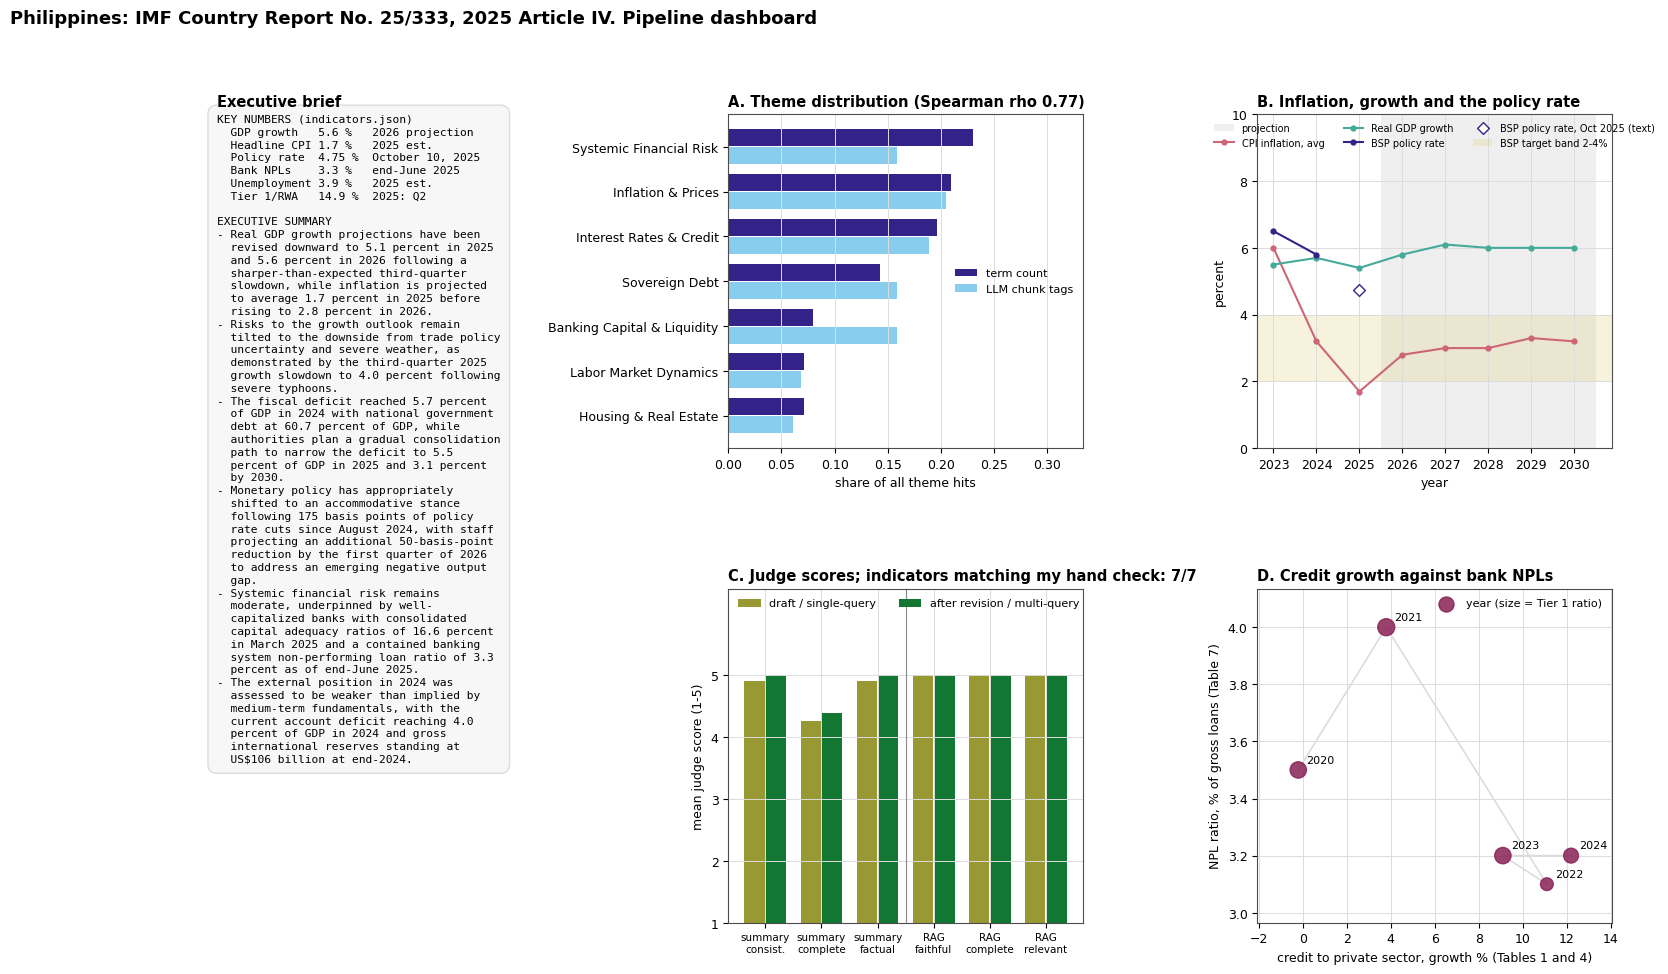

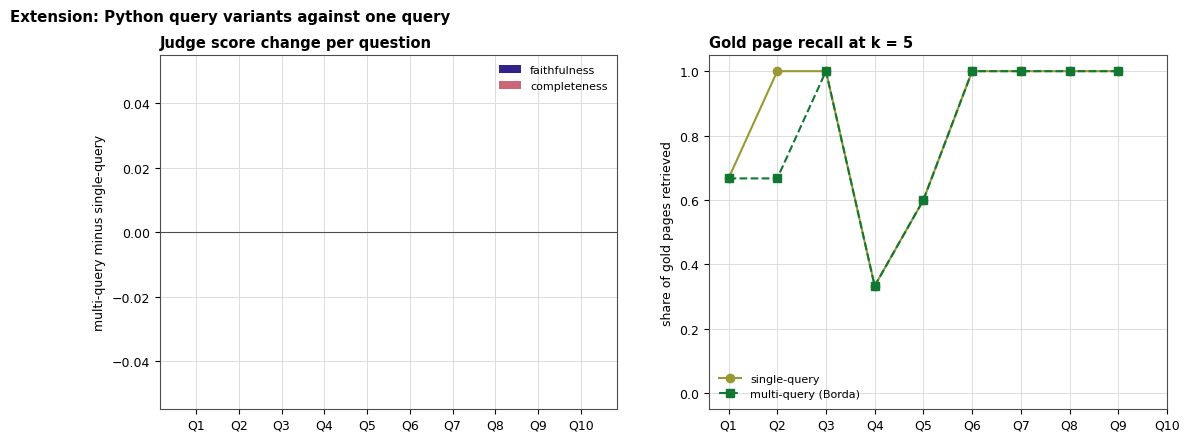

saved artefacts/figures/dashboard.png and artefacts/figures/extension_multiquery.png


In [20]:
TOL = {"indigo": "#332288", "cyan": "#88CCEE", "teal": "#44AA99", "green": "#117733", "olive": "#999933",
       "sand": "#DDCC77", "rose": "#CC6677", "wine": "#882255", "purple": "#AA4499", "pale": "#DCDCDC"}
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.edgecolor": "#4D4D4D",
                     "axes.grid": True, "grid.color": TOL["pale"], "grid.linewidth": 0.7, "legend.fontsize": 8,
                     "legend.frameon": False, "figure.facecolor": "white"})


def brief_text(width: int = 42) -> str:
    labels = {"gdp_growth_forecast_pct": "GDP growth", "headline_inflation_rate_pct": "Headline CPI",
              "central_bank_policy_rate_pct": "Policy rate", "non_performing_loan_ratio": "Bank NPLs",
              "unemployment_rate_pct": "Unemployment", "tier_1_capital_ratio": "Tier 1/RWA"}
    lines = ["KEY NUMBERS (indicators.json)"]
    for f, name in labels.items():
        v = INDICATORS[f]
        period = re.sub(r" \(Table 1\)$", "", (EVIDENCE[f]["period"] or "").replace("as of ", "")).replace("estimate", "est.")   # year from the JSON
        lines.append(f"  {name:<13s}{'n/a' if v is None else f'{v:g} %':<8s}{period}")
    lines += ["", "EXECUTIVE SUMMARY"]
    for b in BULLETS:
        lines += textwrap.wrap(b["text"], width, initial_indent="- ", subsequent_indent="  ")
    return "\n".join(lines)


def panel_themes(ax):
    order = themes_df.sort_values("lexicon_share").index
    y = np.arange(len(order))
    ax.barh(y + 0.2, themes_df.loc[order, "lexicon_share"], 0.38, color=TOL["indigo"], label="term count")
    ax.barh(y - 0.2, themes_df.loc[order, "llm_share"], 0.38, color=TOL["cyan"], label="LLM chunk tags")
    ax.set_yticks(y, themes_df.loc[order, "theme"])
    ax.set_xlabel("share of all theme hits")
    ax.set_title(f"A. Theme distribution (Spearman rho {rho:.2f})", loc="left")
    ax.set_xlim(0, themes_df[["lexicon_share", "llm_share"]].values.max() * 1.45)
    ax.legend(loc="center right")
    ax.grid(axis="y", visible=False)


def panel_paths(ax):
    styles = {"cpi_average": ("CPI inflation, avg", TOL["rose"]), "real_gdp_growth": ("Real GDP growth", TOL["teal"]),
              "policy_rate": ("BSP policy rate", TOL["indigo"])}
    data = series_tidy[series_tidy.series.isin(styles)]
    first_proj = data.loc[data.status == "projection", "year_num"].min()
    if pd.notna(first_proj):
        ax.axvspan(first_proj - 0.5, data.year_num.max() + 0.5, color=TOL["pale"], alpha=0.45, lw=0, label="projection")
    for key, (name, colour) in styles.items():
        d = data[data.series == key].sort_values("year_num")
        table = d[d.source == "table"]
        ax.plot(table.year_num, table.value, marker="o", ms=3.5, color=colour, label=name)
        text_pts = d[d.source == "text"]
        if len(text_pts):
            ax.scatter(text_pts.year_num, text_pts.value, marker="D", s=36, facecolor="white", edgecolor=colour, zorder=3,
                       label=f"{name}, Oct 2025 (text)")
    ax.axhspan(2, 4, color=TOL["sand"], alpha=0.25, lw=0, label="BSP target band 2-4%")
    ax.set_xlabel("year")
    ax.set_ylabel("percent")
    ax.set_title("B. Inflation, growth and the policy rate", loc="left")
    ax.legend(loc="upper center", ncol=3, fontsize=7)   # two rows above the data, clear of the 2023 points
    ax.set_ylim(0, max(10, data.value.max() + 3.5))


def panel_scores(ax):
    rows = [("summary\nconsist.", score_wide["draft|consistency"], score_wide["final|consistency"]),
            ("summary\ncomplete", score_wide["draft|completeness"], score_wide["final|completeness"]),
            ("summary\nfactual", score_wide["draft|factual_alignment"], score_wide["final|factual_alignment"]),
            ("RAG\nfaithful", rag_single.faithfulness, rag_multi.faithfulness),
            ("RAG\ncomplete", rag_single.completeness, rag_multi.completeness),
            ("RAG\nrelevant", rag_single.relevance, rag_multi.relevance)]
    x = np.arange(len(rows))
    ax.bar(x - 0.19, [r[1].mean() for r in rows], 0.36, color=TOL["olive"], label="draft / single-query")
    ax.bar(x + 0.19, [r[2].mean() for r in rows], 0.36, color=TOL["green"], label="after revision / multi-query")
    ax.set_xticks(x, [r[0] for r in rows], fontsize=7.5)
    ax.set_ylim(1, 6.4)
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_ylabel("mean judge score (1-5)")
    agree = int(audit_df.matches_hand.sum())
    ax.set_title(f"C. Judge scores; indicators matching my hand check: {agree}/{len(audit_df)}", loc="left")
    ax.legend(loc="upper left", ncol=2)
    ax.axvline(2.5, color="#888888", lw=0.8)


def panel_credit(ax):
    credit = SERIES[SERIES.series == "private_credit_growth"].set_index("year").value
    npl = SERIES[SERIES.series == "npl_ratio"].set_index("year").value
    tier1 = SERIES[SERIES.series == "tier1_ratio"].set_index("year").value
    years = [y for y in npl.index if y in credit.index]
    xs, ys = credit[years].values, npl[years].values
    ax.plot(xs, ys, color=TOL["pale"], lw=1.2, zorder=1)
    sizes = (tier1.reindex(years).fillna(tier1.mean()) - 13) * 60
    ax.scatter(xs, ys, s=sizes, color=TOL["wine"], alpha=0.85, zorder=2, label="year (size = Tier 1 ratio)")
    for x_, y_, yr in zip(xs, ys, years):
        ax.annotate(yr, (x_, y_), textcoords="offset points", xytext=(6, 5), fontsize=8)
    ax.set_xlabel("credit to private sector, growth % (Tables 1 and 4)")
    ax.set_ylabel("NPL ratio, % of gross loans (Table 7)")
    ax.set_title("D. Credit growth against bank NPLs", loc="left")
    ax.legend(loc="upper right")
    ax.margins(0.15)


fig = plt.figure(figsize=(18, 10.5))
grid = fig.add_gridspec(2, 3, width_ratios=[0.95, 1, 1], hspace=0.42, wspace=0.5)
ax_brief = fig.add_subplot(grid[:, 0])
ax_brief.axis("off")
brief = brief_text()
size = min(8.6, 560 / ((brief.count("\n") + 1) * 1.35))  # shrink the font when the bullets are long
ax_brief.text(0.0, 1.0, brief, va="top", ha="left", family="monospace", fontsize=size, linespacing=1.35,
              transform=ax_brief.transAxes,
              bbox={"boxstyle": "round,pad=0.8", "facecolor": "#F7F7F7", "edgecolor": TOL["pale"]})
ax_brief.set_title("Executive brief", loc="left")
panel_themes(fig.add_subplot(grid[0, 1]))
panel_paths(fig.add_subplot(grid[0, 2]))
panel_scores(fig.add_subplot(grid[1, 1]))
panel_credit(fig.add_subplot(grid[1, 2]))
fig.suptitle(f"{opt.country}: {opt.label}. Pipeline dashboard", x=0.01, ha="left", fontsize=13, fontweight="bold")
dash_path = OUT / "figures" / "dashboard.png"
fig.savefig(dash_path, dpi=300, bbox_inches="tight")
plt.show()

fig2, (e1, e2) = plt.subplots(1, 2, figsize=(13, 4.6))
q = np.arange(len(QUESTIONS))
for k, (axis_name, colour) in enumerate([("faithfulness", TOL["indigo"]), ("completeness", TOL["rose"])]):
    e1.bar(q + (k - 0.5) * 0.38, rag_multi[axis_name] - rag_single[axis_name], 0.36, color=colour, label=axis_name)
e1.axhline(0, color="#4D4D4D", lw=0.8)
e1.set_xticks(q, rag_single.qid)
e1.set_ylabel("multi-query minus single-query")
e1.set_title("Judge score change per question", loc="left")
e1.legend()
e2.plot(q, rag_single.gold_recall, "o-", color=TOL["olive"], label="single-query")
e2.plot(q, rag_multi.gold_recall, "s--", color=TOL["green"], label="multi-query (Borda)")
e2.set_xticks(q, rag_single.qid)
e2.set_ylim(-0.05, 1.05)
e2.set_ylabel("share of gold pages retrieved")
e2.set_title("Gold page recall at k = 5", loc="left")
e2.legend()
fig2.suptitle("Extension: Python query variants against one query", x=0.01, ha="left", fontweight="bold")
ext_path = OUT / "figures" / "extension_multiquery.png"
fig2.savefig(ext_path, dpi=300, bbox_inches="tight")
plt.show()
print("saved", dash_path, "and", ext_path)

**Step 20. Run record**

This prints every prompt and a table of the model calls.

In [21]:
for name, p in PROMPTS.items():
    print(f"=== {name} ===\n[system] {p['system']}\n[user template]\n{p['user'].template}\n")

calls = pd.DataFrame(CALLS)
calls["stage"] = calls.step.str.split("/").str[0]
by_stage = calls.groupby(["stage", "role", "model"]).agg(calls=("step", "size"), live=("source", lambda s: int((s == "live").sum())),
                                                         seconds=("seconds", "sum"), out_tokens=("tokens", "sum"))
print(by_stage.to_string())
TOTALS = call_totals()
print("\n" + json.dumps(TOTALS, indent=1))

expected = ["cleaning", "sections", "chunks", "section_summaries", "executive_summary", "themes", "insights", "indicators",
            "indicator_evidence", "indicator_fallbacks", "indicator_audit", "timeseries", "rag_eval",
            "extension_multiquery", "long_tables"]
save("call_log", CALLS)
save("run_record", {"totals": TOTALS, "pdf": str(PDF), "pdf_sha256": PDF_SHA256, "settings": vars(opt),
                    "prompts": {k: {"system": v["system"], "user": v["user"].template} for k, v in PROMPTS.items()},
                    "artefacts": expected + ["call_log", "run_record"]})
missing = [n for n in expected if not (OUT / "json" / f"{n}.json").exists()]
assert not missing, f"missing outputs: {missing}"
assert (OUT / "figures" / "dashboard.png").exists() and (OUT / "figures" / "extension_multiquery.png").exists()
print(f"\nall {len(expected) + 2} JSON files and both figures are in {OUT}/")

=== section_summary ===
[system] You write short briefing notes on IMF Article IV staff reports for a finance ministry reader.
You only use facts that are in the text you are given and you copy numbers exactly as printed.
[user template]
Summarise section $sid, "$title" (PDF pages $pages), of the IMF report on the Philippines.
Rules:
- At most $limit words of plain prose, no bullet points, no heading.
- Start with the main finding or recommendation, then the key figures with their year and unit.
- Keep the IMF's own judgement words, for example "appropriate", "moderate", "tilted to the downside".
- If the section is mostly a table or a set of charts, say what it reports and give the two or three most important numbers.
- In figures_used, list every number you used exactly as it is written in the text.

SECTION TEXT
$text

=== summary_grade ===
[system] You check summaries of IMF report sections against their source text. You are strict: a number that is
not in the source, or a claim th

**Output files**

JSON results are in `artefacts/json/` and figures are in `artefacts/figures/`.